# Data Analytics in Supply Chain Management — Project Part 1
## Dataset 1: Manufacturing Energy Consumption (Regression)

**Course:** Data Analytics in Supply Chain Management — Fall 2026  
**Project:** Project Part 1  
**Use Case:** Manufacturing Energy Consumption (Regression)  
**Dataset file:** `regression_manufacturing.csv`

### Purpose

This notebook performs the **Exploratory Data Analysis (EDA)** and **brainstorming** required for Dataset 1. It follows the project brief and grading criteria: dataset dimensions and statistical features, data types and missing values, categorical analysis, numerical-variable analysis, outlier detection, relationships among variables, bonus visualizations, and evidence-supported brainstorming.

> **Scope discipline:** Project Part 1 asks us to explore the dataset and later build regression models. This notebook therefore focuses on EDA and hypothesis generation rather than training a final regression model.

### Scenario

The smart-factory scenario asks an analytics team to understand how production, machine condition, maintenance, human, and environmental factors are associated with unusually high energy use, while preparing the data for later prediction of `Energy_Consumption_kWh`.

### Analytical task

The dataset is described in the project brief as a machine-day regression problem with `Energy_Consumption_kWh` as the dependent variable. The brief explicitly notes that the underlying data may contain **nonlinear patterns**, including overload and overheating thresholds, U-shaped operating regions, diminishing returns, and interactions between machine condition and production requirements.

**Primary target:** `Energy_Consumption_kWh`

**Important:** The raw CSV is loaded without modifying its values. Any date parsing or temporary variables used for EDA are created on copies.


## Figure 1 — Project use case

The uploaded project image frames the problem around five groups of factors: **machine settings**, **production volume**, **environmental conditions**, **equipment condition and maintenance**, and the resulting **energy consumption (kWh)**.

The image is reproduced below for direct connection between the project scenario and the variables examined in this notebook.


## Figure 1 — Project use case

The analysis investigates how production demand, machine operating conditions, maintenance, material properties, operator experience, and ambient conditions relate to manufacturing energy consumption. This text-based summary avoids a fragile external image path and keeps the notebook portable.

**Regression target:** `Energy_Consumption_kWh`. `Observation_ID` is an identifier, not a predictive feature.

## 1. Reproducibility and imports

The analysis uses standard Python data-analysis and visualization libraries. A fixed random seed is used for sampling-based visualizations so that the notebook is reproducible.


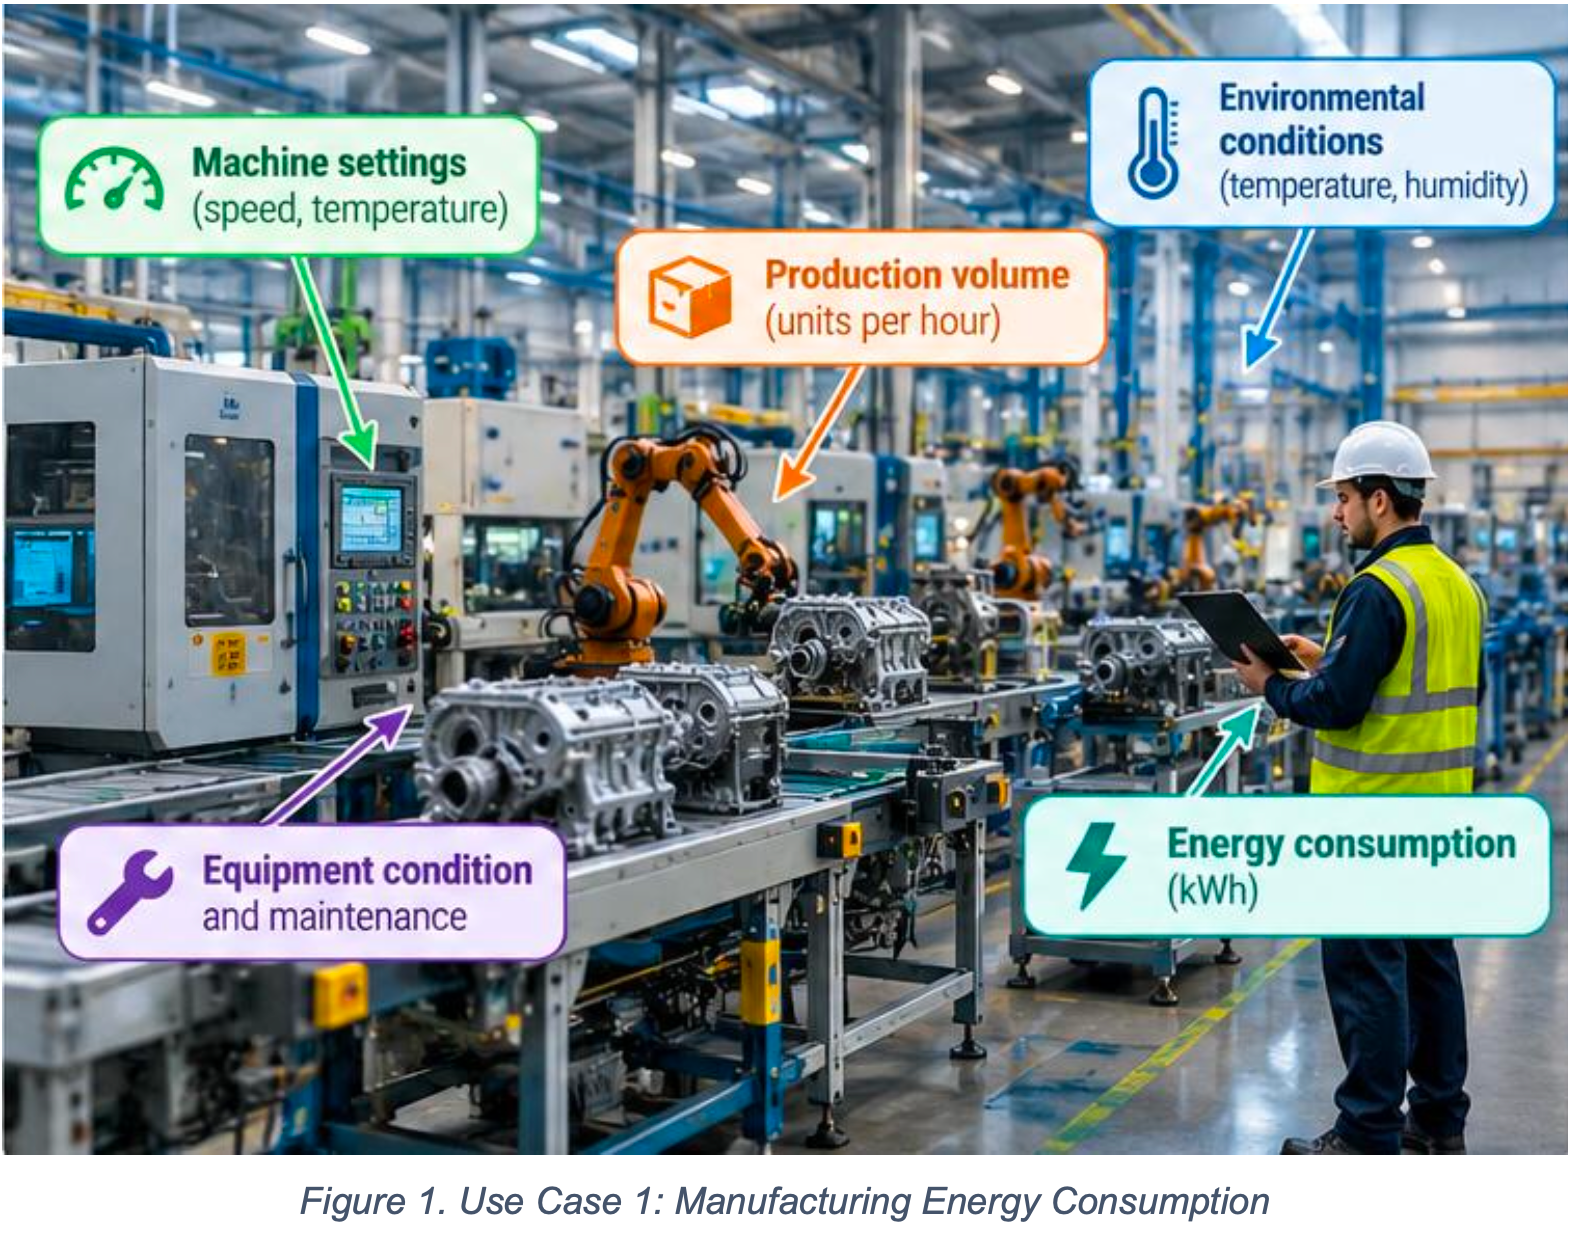

In [34]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from IPython.display import display, Image
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pandas.plotting import parallel_coordinates

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

BASE_DIR = Path.cwd()
DATA_PATH = Path("../MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/data/regression_manufacturing.csv")
figure_candidates = [
    BASE_DIR / "Figure_1_Manufacturing_Energy_Consumption_Use_Case.png",
    BASE_DIR / "images" / "Figure_1_Manufacturing_Energy_Consumption_Use_Case.png",
    BASE_DIR / "assets" / "Figure_1_Manufacturing_Energy_Consumption_Use_Case.png",
    BASE_DIR / "figures" / "Figure_1_Manufacturing_Energy_Consumption_Use_Case.png",
]
FIGURE_PATH = next((p for p in figure_candidates if p.exists()), None)
if FIGURE_PATH is not None:
    display(Image(filename=str(FIGURE_PATH), width=1000))
else:
    print("Contextual use-case image is not present in the repository. The analysis does not depend on it; add it under images/ or the project root if it is required for submission.")


In [2]:
from pathlib import Path

PLOTS_DIR = Path("plots-1-updated")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

def save_and_show(filename):
    """Save the current matplotlib figure as a high-resolution PNG, then display it."""
    output_path = PLOTS_DIR / filename
    plt.savefig(output_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved plot: {output_path.resolve()}")
    plt.show()


## 2. Load the raw dataset

The project brief describes **10,000 machine-day observations**, but the supplied CSV should be checked rather than assumed. We therefore report the actual dimensions of the uploaded file and explicitly flag any discrepancy.

No rows or values are removed at this stage.


In [3]:
df_raw = pd.read_csv(DATA_PATH)

# Keep the imported CSV immutable. Inspection shows the intended dataset ends at
# Observation_ID 10000 (the first 10,000 data rows); 250 additional rows follow,
# repeating IDs 1–10,000. Those appended rows contain 228 exact copies and 22
# non-identical ID twins. The canonical first 10,000 rows are used provisionally.
TARGET = "Energy_Consumption_kWh"
ID_COL = "Observation_ID"
DATE_COL = "Production_Date"
EXPECTED_N = 10_000

df_appended_rows = df_raw.iloc[EXPECTED_N:].copy()
df_canonical = df_raw.iloc[:EXPECTED_N].copy()
assert len(df_canonical) == EXPECTED_N
assert df_canonical[ID_COL].is_unique, "Canonical first 10,000 rows should have unique IDs"
assert df_canonical[ID_COL].min() == 1 and df_canonical[ID_COL].max() == 10_000

# The original 10,000-row block has no complete duplicate rows. Preserve it and
# use a separate working copy for corrections and EDA.
df_exact_deduped = df_canonical.drop_duplicates().copy()
expected_machine_types = {"CNC_Mill", "CNC_Lathe", "CNC_Grinder", "Laser_Cutter"}
expected_shifts = {"Day", "Evening", "Night"}

# Each Machine_ID has one dominant/documented type. Correct the five Tree labels
# using the type recorded for that machine elsewhere in the canonical data.
machine_type_map = (df_exact_deduped.loc[df_exact_deduped["Machine_Type"].isin(expected_machine_types)]
                    .groupby("Machine_ID")["Machine_Type"]
                    .agg(lambda s: s.mode().iat[0] if not s.mode().empty else np.nan))
df_pre_outlier = df_exact_deduped.copy()
tree_mask = df_pre_outlier["Machine_Type"].eq("Tree")
df_pre_outlier.loc[tree_mask, "Machine_Type"] = df_pre_outlier.loc[tree_mask, "Machine_ID"].map(machine_type_map)

# Invalid 'Dream' shift labels are not inferable from other fields: retain those
# records but mark Shift missing, rather than dropping five otherwise usable rows.
dream_mask = df_pre_outlier["Shift"].eq("Dream")
df_pre_outlier.loc[dream_mask, "Shift"] = np.nan

# Extreme values are retained in df_pre_outlier for transparent audit tables, but
# provisionally set to missing in the analytical copy. These thresholds are a
# conservative cleaning decision pending confirmation from the lecturer/data owner.
extreme_thresholds = {
    "Average_Machine_Temperature_C": 120,
    "Cycle_Time_sec": 200,
    "Vibration_mm_s": 6,
    TARGET: 800,
}
extreme_audit_counts = {col: int((df_pre_outlier[col] > threshold).sum()) for col, threshold in extreme_thresholds.items()}
df = df_pre_outlier.copy()
for col, threshold in extreme_thresholds.items():
    df.loc[df[col] > threshold, col] = np.nan

df[DATE_COL] = pd.to_datetime(df[DATE_COL], errors="coerce")
df_pre_outlier[DATE_COL] = pd.to_datetime(df_pre_outlier[DATE_COL], errors="coerce")

print(f"Raw file shape: {df_raw.shape}")
print(f"Canonical block selected: rows 1–{EXPECTED_N} (Observation_ID 1–10,000), shape={df_canonical.shape}")
print(f"Appended rows after the canonical block: {len(df_appended_rows):,}")
print(f"Exact duplicates in canonical block: {int(df_canonical.duplicated().sum()):,}")
canonical_rows_as_tuples = set(df_canonical.astype(object).where(pd.notna(df_canonical), "__MISSING__").itertuples(index=False, name=None))
appended_exact_copy_mask = df_appended_rows.astype(object).where(pd.notna(df_appended_rows), "__MISSING__").apply(lambda row: tuple(row.tolist()) in canonical_rows_as_tuples, axis=1)
print(f"Appended rows that exactly copy a canonical row: {int(appended_exact_copy_mask.sum()):,}")
print(f"Appended rows with IDs already in canonical block: {int(df_appended_rows[ID_COL].isin(df_canonical[ID_COL]).sum()):,}")
print(f"Machine_Type 'Tree' rows corrected from Machine_ID mapping: {int(tree_mask.sum())}")
print(f"Shift 'Dream' rows retained with Shift set missing: {int(dream_mask.sum())}")
print("Provisional extreme values set to missing by column:", extreme_audit_counts)
print(f"Final EDA copy shape: {df.shape}; df_raw remains untouched.")
display(df.head())


Raw file shape: (10250, 20)
Canonical block selected: rows 1–10000 (Observation_ID 1–10,000), shape=(10000, 20)
Appended rows after the canonical block: 250
Exact duplicates in canonical block: 0
Appended rows that exactly copy a canonical row: 228
Appended rows with IDs already in canonical block: 250
Machine_Type 'Tree' rows corrected from Machine_ID mapping: 5
Shift 'Dream' rows retained with Shift set missing: 5
Provisional extreme values set to missing by column: {'Average_Machine_Temperature_C': 94, 'Cycle_Time_sec': 101, 'Vibration_mm_s': 92, 'Energy_Consumption_kWh': 95}
Final EDA copy shape: (10000, 20); df_raw remains untouched.


,Observation_ID,Production_Date,Machine_ID,Machine_Type,Shift,Machine_Age_years,Operating_Hours_per_Day,Production_Volume_units,Product_Complexity_Index,Material_Hardness_HB,Cycle_Time_sec,Spindle_Load_pct,Average_Machine_Temperature_C,Vibration_mm_s,Tool_Wear_Index,Days_Since_Maintenance,Operator_Experience_years,Ambient_Temperature_C,Humidity_pct,Energy_Consumption_kWh
0,1,2025-06-23,M042,Laser_Cutter,Day,3.130,17.990,683,7.850,199.000,84.240,87.960,78.170,2.098,0.408,22.800,6.020,19.470,59.060,NaN
1,2,2025-04-14,M012,Laser_Cutter,Day,5.280,14.720,584,5.330,236.900,69.630,65.000,74.680,2.473,0.685,81.600,5.120,21.310,41.700,337.380
2,3,2025-06-21,M004,CNC_Grinder,Day,9.050,20.860,580,2.340,272.000,98.710,57.190,78.100,3.026,0.459,31.100,16.190,26.210,45.390,291.230
3,4,2025-12-19,M006,Laser_Cutter,Day,14.140,15.460,570,6.550,293.600,70.350,81.310,78.050,3.963,0.464,31.000,16.590,7.670,74.090,381.940
4,5,2025-01-29,M049,CNC_Lathe,Evening,2.670,17.910,651,5.140,221.400,62.870,58.250,79.530,1.461,0.330,14.400,6.720,12.460,76.650,242.100


### 2.1 Dataset integrity checks

The project brief states that `Observation_ID` is a unique row identifier and should not be used as a predictive feature. We check uniqueness, duplicate rows, date coverage, and unexpected categorical levels.

These checks are **diagnostic only**. The raw dataset remains unchanged.


In [4]:
print("Raw rows in CSV:", len(df_raw))
print("Canonical rows selected (first 10,000):", len(df_canonical))
print("Appended rows excluded (rows after Observation_ID 10000 block):", len(df_appended_rows))
print("Unique Observation_ID in canonical block:", df_canonical[ID_COL].nunique())
print("Duplicate Observation_ID rows in canonical block:", int(df_canonical[ID_COL].duplicated(keep=False).sum()))
print("Exact duplicates in canonical block:", int(df_canonical.duplicated().sum()))
canonical_rows_as_tuples = set(df_canonical.astype(object).where(pd.notna(df_canonical), "__MISSING__").itertuples(index=False, name=None))
appended_exact_copy_mask = df_appended_rows.astype(object).where(pd.notna(df_appended_rows), "__MISSING__").apply(lambda row: tuple(row.tolist()) in canonical_rows_as_tuples, axis=1)
print("Appended rows that exactly copy a canonical row:", int(appended_exact_copy_mask.sum()))

# Show all 22 non-identical twins found by comparing the appended 250 records to
# their canonical ID counterparts. This is an audit, not the basis for choosing
# among canonical records: the first 10,000-row block is the provisional source.
canonical_by_id = df_canonical.set_index(ID_COL, drop=False)
twin_rows = []
for _, extra in df_appended_rows.iterrows():
    oid = extra[ID_COL]
    if oid in canonical_by_id.index:
        original = canonical_by_id.loc[oid]
        if isinstance(original, pd.DataFrame):
            original = original.iloc[0]
        if not extra.equals(original):
            changed = [c for c in df_raw.columns if not (pd.isna(extra[c]) and pd.isna(original[c])) and extra[c] != original[c]]
            twin_rows.append({"Observation_ID": oid, "canonical_row_position_1based": int(oid),
                              "appended_row_position_1based": int(extra.name + 1),
                              "differing_columns": ", ".join(changed)})
conflicting_id_audit = pd.DataFrame(twin_rows).sort_values("Observation_ID")
print(f"Non-identical appended ID twins: {len(conflicting_id_audit)} rows (IDs listed below)")
display(conflicting_id_audit)
print("\nRows corrected/flagged in canonical analysis copy:")
display(df_pre_outlier.loc[tree_mask | dream_mask, [ID_COL, "Machine_ID", "Machine_Type", "Shift", DATE_COL, TARGET]])


Raw rows in CSV: 10250
Canonical rows selected (first 10,000): 10000
Appended rows excluded (rows after Observation_ID 10000 block): 250
Unique Observation_ID in canonical block: 10000
Duplicate Observation_ID rows in canonical block: 0
Exact duplicates in canonical block: 0
Appended rows that exactly copy a canonical row: 228
Non-identical appended ID twins: 22 rows (IDs listed below)


,Observation_ID,canonical_row_position_1based,appended_row_position_1based,differing_columns
12,30,30,10161,Average_Machine_Temperature_C
11,32,32,10158,Energy_Consumption_kWh
8,120,120,10141,Vibration_mm_s
19,959,959,10231,Vibration_mm_s
6,1225,1225,10130,Cycle_Time_sec
7,1513,1513,10139,Energy_Consumption_kWh
14,2909,2909,10194,Vibration_mm_s
3,2928,2928,10075,Vibration_mm_s
13,3899,3899,10184,Average_Machine_Temperature_C
20,4382,4382,10235,Energy_Consumption_kWh



Rows corrected/flagged in canonical analysis copy:


,Observation_ID,Machine_ID,Machine_Type,Shift,Production_Date,Energy_Consumption_kWh
2407,2408,M005,CNC_Mill,NaN,2025-05-28,272.760
3175,3176,M031,Laser_Cutter,Night,2025-11-30,631.590
3657,3658,M042,Laser_Cutter,NaN,2025-06-16,379.330
3963,3964,M001,CNC_Grinder,NaN,2025-09-05,351.620
4094,4095,M040,CNC_Grinder,Day,2025-05-08,195.180
4289,4290,M027,CNC_Mill,Night,2025-03-11,367.310
5793,5794,M032,CNC_Lathe,NaN,2025-02-07,209.010
6073,6074,M037,Laser_Cutter,NaN,2025-03-12,381.240
8500,8501,M045,CNC_Grinder,Evening,2025-10-28,286.880
8629,8630,M020,CNC_Mill,Evening,2025-10-18,257.660


## Cleaning decisions and dataset-boundary audit

`df_raw` is preserved unchanged. A positional audit shows that the CSV contains 10,250 data rows, but its first 10,000 rows have unique `Observation_ID` values 1–10,000. The following 250 rows restart with previously seen IDs. These appended rows contain 228 exact copies and 22 non-identical ID twins. **This notebook provisionally treats rows 1–10,000 as the canonical dataset and excludes the appended 250 rows from EDA**, rather than arbitrarily selecting among duplicate/twin records. Confirm this boundary with the lecturer/data owner before final submission.

Five `Machine_Type == "Tree"` records are corrected from the unique type mapping of their `Machine_ID`; five `Shift == "Dream"` values are set to missing because the intended shift cannot be inferred safely. For the four pre-specified extreme thresholds—temperature >120, cycle time >200, vibration >6, and energy >800—the affected values are provisionally set to missing in `df` but remain visible in `df_pre_outlier` and `df_raw` for audit. This is a transparent working decision, not proof that the values are errors. Ask the lecturer/data owner to confirm these thresholds and whether those values were deliberately injected. Only 22 of the 387 flagged extreme rows have a visible appended twin; the cause of the remaining extremes cannot be established from this CSV alone.

All subsequent EDA summaries and figures use the canonical analysis copy `df`, except explicit outlier audit tables, which use `df_pre_outlier` so the original extreme values remain inspectable.



CLEANING SUMMARY
                                     value
raw_csv_rows                         10250
canonical_rows_used                  10000
appended_rows_excluded                 250
exact_duplicates_in_canonical_block      0
Tree_labels_corrected                    5
Dream_shifts_set_missing                 5
final_analysis_rows_retained         10000
extreme_values_set_missing             382

BOUNDARY VALUES


,feature,limit_value,count,pct_of_clean_rows
0,Operating_Hours_per_Day,6,38,0.380
1,Operating_Hours_per_Day,24,125,1.250
2,Days_Since_Maintenance,100,127,1.270
3,Operator_Experience_years,22,58,0.580
4,Ambient_Temperature_C,5,261,2.610



MISSINGNESS RATE BY Machine_Type


,Machine_Type,n_rows,Shift_missing_pct,Cycle_Time_sec_missing_pct,Average_Machine_Temperature_C_missing_pct,Vibration_mm_s_missing_pct,Tool_Wear_Index_missing_pct,Humidity_pct_missing_pct,Energy_Consumption_kWh_missing_pct
0,CNC_Grinder,2236,0.040,1.210,5.590,5.550,5.770,3.530,4.960
1,CNC_Lathe,2208,0.050,1.040,3.990,6.660,6.610,2.670,4.940
2,CNC_Mill,3606,0.030,0.940,4.550,6.320,5.850,3.050,4.580
3,Laser_Cutter,1950,0.100,0.870,6.000,4.770,5.850,2.670,5.640



MISSINGNESS RATE BY Machine_ID


...


SPEARMAN CORRELATION MATRIX


,Machine_Age_years,Operating_Hours_per_Day,Production_Volume_units,Product_Complexity_Index,Material_Hardness_HB,Cycle_Time_sec,Spindle_Load_pct,Average_Machine_Temperature_C,Vibration_mm_s,Tool_Wear_Index,Days_Since_Maintenance,Operator_Experience_years,Ambient_Temperature_C,Humidity_pct,Energy_Consumption_kWh
Machine_Age_years,1.000,-0.002,-0.017,0.018,0.005,0.037,0.010,0.003,0.693,-0.002,-0.008,0.010,0.017,-0.019,0.122
Operating_Hours_per_Day,-0.002,1.000,0.676,0.016,0.012,0.009,0.017,0.414,0.114,0.259,0.015,-0.015,0.002,0.004,0.372
Production_Volume_units,-0.017,0.676,1.000,-0.364,-0.204,-0.619,-0.246,0.118,-0.019,0.118,0.001,-0.010,0.011,-0.003,0.086
Product_Complexity_Index,0.018,0.016,-0.364,1.000,0.456,0.594,0.765,0.462,0.248,0.114,-0.004,-0.010,-0.006,0.004,0.553
Material_Hardness_HB,0.005,0.012,-0.204,0.456,1.000,0.339,0.522,0.338,0.232,0.245,0.002,-0.000,-0.014,0.011,0.384
Cycle_Time_sec,0.037,0.009,-0.619,0.594,0.339,1.000,0.465,0.301,0.180,0.092,0.006,-0.005,-0.008,0.003,0.309
Spindle_Load_pct,0.010,0.017,-0.246,0.765,0.522,0.465,1.000,0.592,0.306,0.142,0.006,-0.005,-0.007,0.005,0.524
Average_Machine_Temperature_C,0.003,0.414,0.118,0.462,0.338,0.301,0.592,1.000,0.288,0.338,0.138,-0.008,0.015,-0.026,0.539
Vibration_mm_s,0.693,0.114,-0.019,0.248,0.232,0.180,0.306,0.288,1.000,0.435,0.312,-0.003,0.007,-0.017,0.467
Tool_Wear_Index,-0.002,0.259,0.118,0.114,0.245,0.092,0.142,0.338,0.435,1.000,0.764,-0.003,-0.011,0.003,0.473



PEARSON CORRELATIONS AFTER EXCLUDING ANY ROW IN AN EXTREME GROUP
Rows retained after removing any row flagged by the four extreme rules: 9,625 of 10,000


,Machine_Age_years,Operating_Hours_per_Day,Production_Volume_units,Product_Complexity_Index,Material_Hardness_HB,Cycle_Time_sec,Spindle_Load_pct,Average_Machine_Temperature_C,Vibration_mm_s,Tool_Wear_Index,Days_Since_Maintenance,Operator_Experience_years,Ambient_Temperature_C,Humidity_pct,Energy_Consumption_kWh
Machine_Age_years,1.000,0.000,-0.003,0.018,0.006,0.033,0.012,0.002,0.688,-0.006,-0.015,0.014,0.016,-0.017,0.121
Operating_Hours_per_Day,0.000,1.000,0.642,0.022,0.016,0.015,0.018,0.426,0.124,0.253,0.004,-0.015,0.002,-0.002,0.371
Production_Volume_units,-0.003,0.642,1.000,-0.374,-0.221,-0.643,-0.253,0.106,-0.010,0.100,-0.002,-0.015,0.014,-0.014,0.087
Product_Complexity_Index,0.018,0.022,-0.374,1.000,0.465,0.604,0.763,0.474,0.258,0.119,0.003,-0.005,-0.009,0.008,0.561
Material_Hardness_HB,0.006,0.016,-0.221,0.465,1.000,0.349,0.538,0.353,0.247,0.251,0.007,0.008,-0.011,0.008,0.397
Cycle_Time_sec,0.033,0.015,-0.643,0.604,0.349,1.000,0.473,0.307,0.180,0.097,0.008,-0.003,-0.010,0.008,0.313
Spindle_Load_pct,0.012,0.018,-0.253,0.763,0.538,0.473,1.000,0.609,0.319,0.148,0.014,0.002,-0.010,0.005,0.538
Average_Machine_Temperature_C,0.002,0.426,0.106,0.474,0.353,0.307,0.609,1.000,0.305,0.352,0.153,-0.006,0.008,-0.024,0.564
Vibration_mm_s,0.688,0.124,-0.010,0.258,0.247,0.180,0.319,0.305,1.000,0.461,0.338,-0.000,0.008,-0.016,0.492
Tool_Wear_Index,-0.006,0.253,0.100,0.119,0.251,0.097,0.148,0.352,0.461,1.000,0.805,-0.005,-0.013,-0.003,0.518


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_12_Pearson_Correlation_Lower_Triangle.png


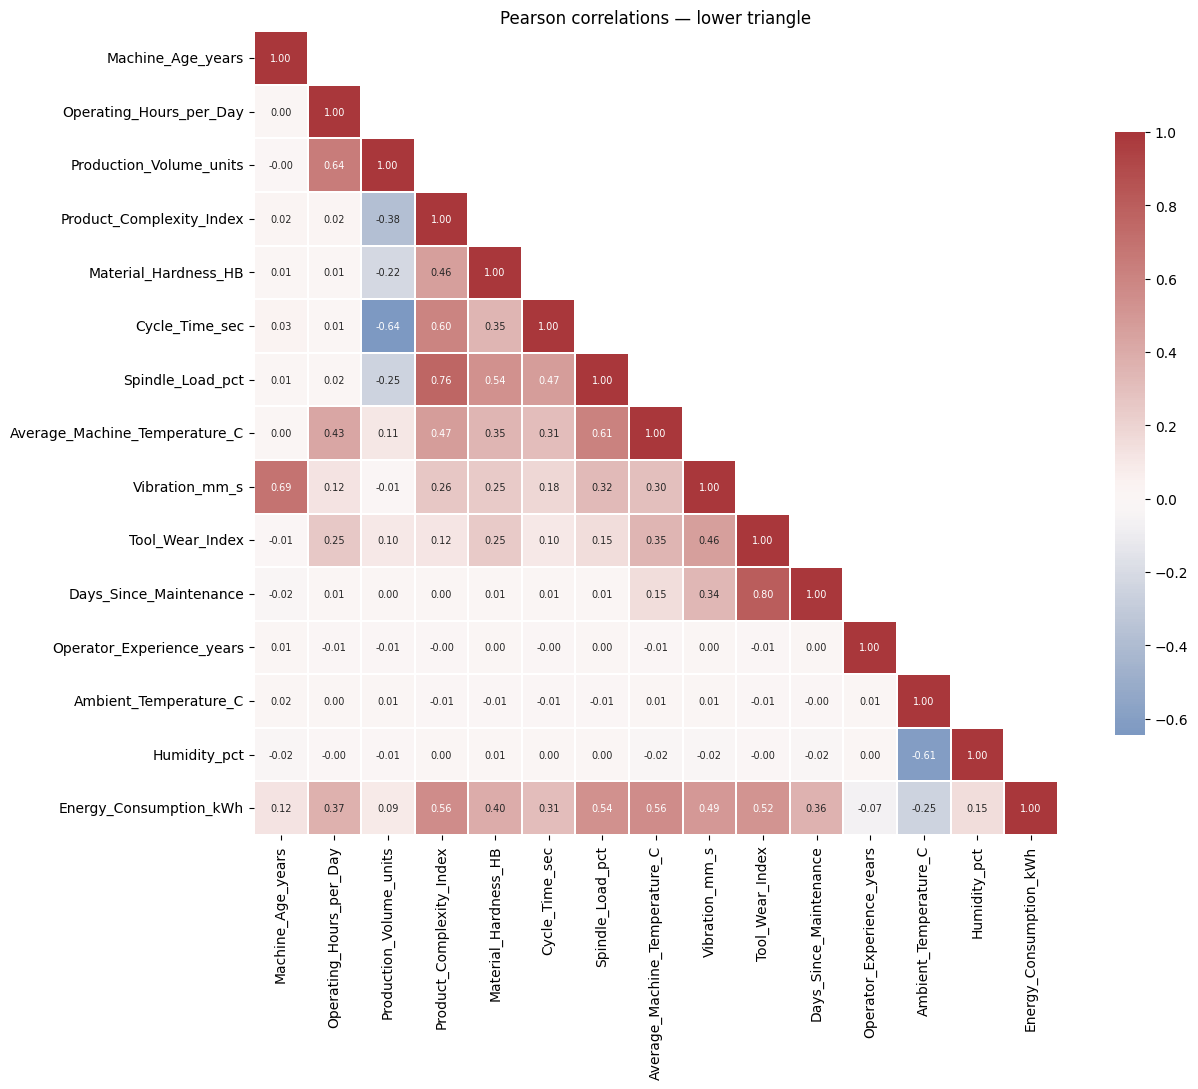


VARIANCE INFLATION FACTORS (complete cases; not a causal test)


,feature,VIF
2,Production_Volume_units,6.306
9,Tool_Wear_Index,5.095
5,Cycle_Time_sec,4.332
1,Operating_Hours_per_Day,4.285
8,Vibration_mm_s,4.024
10,Days_Since_Maintenance,3.778
6,Spindle_Load_pct,3.746
3,Product_Complexity_Index,2.993
0,Machine_Age_years,2.910
7,Average_Machine_Temperature_C,2.327



BINNED ENERGY SUMMARY: Ambient_Temperature_C


,bin,count,mean,median,std
0,"(4.999, 10.0]",1769,356.151,349.640,63.114
1,"(10.0, 15.0]",2003,312.206,305.360,61.944
2,"(15.0, 20.0]",1641,284.527,277.560,59.739
3,"(20.0, 25.0]",1859,281.319,274.860,60.280
4,"(25.0, 30.0]",1804,297.983,290.080,63.290
5,"(30.0, 35.0]",422,334.712,333.705,62.881
6,"(35.0, 40.0]",7,474.927,439.890,101.377



BINNED ENERGY SUMMARY: Humidity_pct


...


INTERACTION TABLE: DAYS SINCE MAINTENANCE × TOOL WEAR


count                                   \
Tool_Wear_Band         (-0.001, 0.2] (0.2, 0.4] (0.4, 0.6] (0.6, 0.8]   
Maintenance_Delay_Band                                                  
(-0.001, 15.0]                   367       1134        165          2   
(15.0, 30.0]                     165       1788       1005         29   
(30.0, 45.0]                      11        603       1334        166   
(45.0, 60.0]                       0        100        700        347   
(60.0, 80.0]                       0          4        188        408   
(80.0, 100.0]                      0          1          8        156   

                                           mean                        \
Tool_Wear_Band         (0.8, 1.0] (-0.001, 0.2] (0.2, 0.4] (0.4, 0.6]   
Maintenance_Delay_Band                                                  
(-0.001, 15.0]                  0       252.350    292.350    333.270   
(15.0, 30.0]                    0       253.050    285.260    321.150   
(30.0, 45.0]                    2       225.770    277.200    312.500   
(45.0, 60.0]                   11           NaN    266.660    307.890   
(60.0, 80.0]                   62           NaN    268.150    309.170   
(80.0, 100.0]                 170           NaN    312.290    349.860   

                                                    median             \
Tool_Wear_Band         (0.6, 0.8] (0.8, 1.0] (-0.001, 0.2] (0.2, 0.4]   
Maintenance_Delay_Band                                                  
(-0.001, 15.0]            484.260        NaN       249.560    287.090   
(15.0, 30.0]              374.710        NaN       248.010    279.770   
(30.0, 45.0]              361.110    496.670       209.740    270.160   
(45.0, 60.0]              348.680    384.990           NaN    262.790   
(60.0, 80.0]              359.040    415.280           NaN    267.640   
(80.0, 100.0]             381.320    432.910           NaN    312.290   

                                                         
Tool_Wear_Band         (0.4, 0.6] (0.6, 0.8] (0.8, 1.0]  
Maintenance_Delay_Band                                   
(-0.001, 15.0]            330.290    484.260        NaN  
(15.0, 30.0]              315.360    373.210        NaN  
(30.0, 45.0]              307.190    358.820    496.670  
(45.0, 60.0]              301.830    342.360    373.290  
(60.0, 80.0]              299.060    348.660    410.440  
(80.0, 100.0]             351.060    376.020    425.360


ENERGY BY MACHINE_ID — ALL MACHINES, SORTED BY MEAN ENERGY


,n,mean,median,std
Machine_ID,,,,
M041,195,355.861,351.140,64.720
M039,197,348.530,340.590,62.278
M031,176,346.503,340.645,73.790
M023,176,341.484,327.800,65.361
M006,187,338.756,331.490,69.030
M012,190,335.627,330.070,61.235
M042,192,333.476,329.095,69.791
M016,178,330.746,321.070,67.384
M045,192,322.157,312.945,60.191


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_Mean_Energy_by_All_50_Machines.png


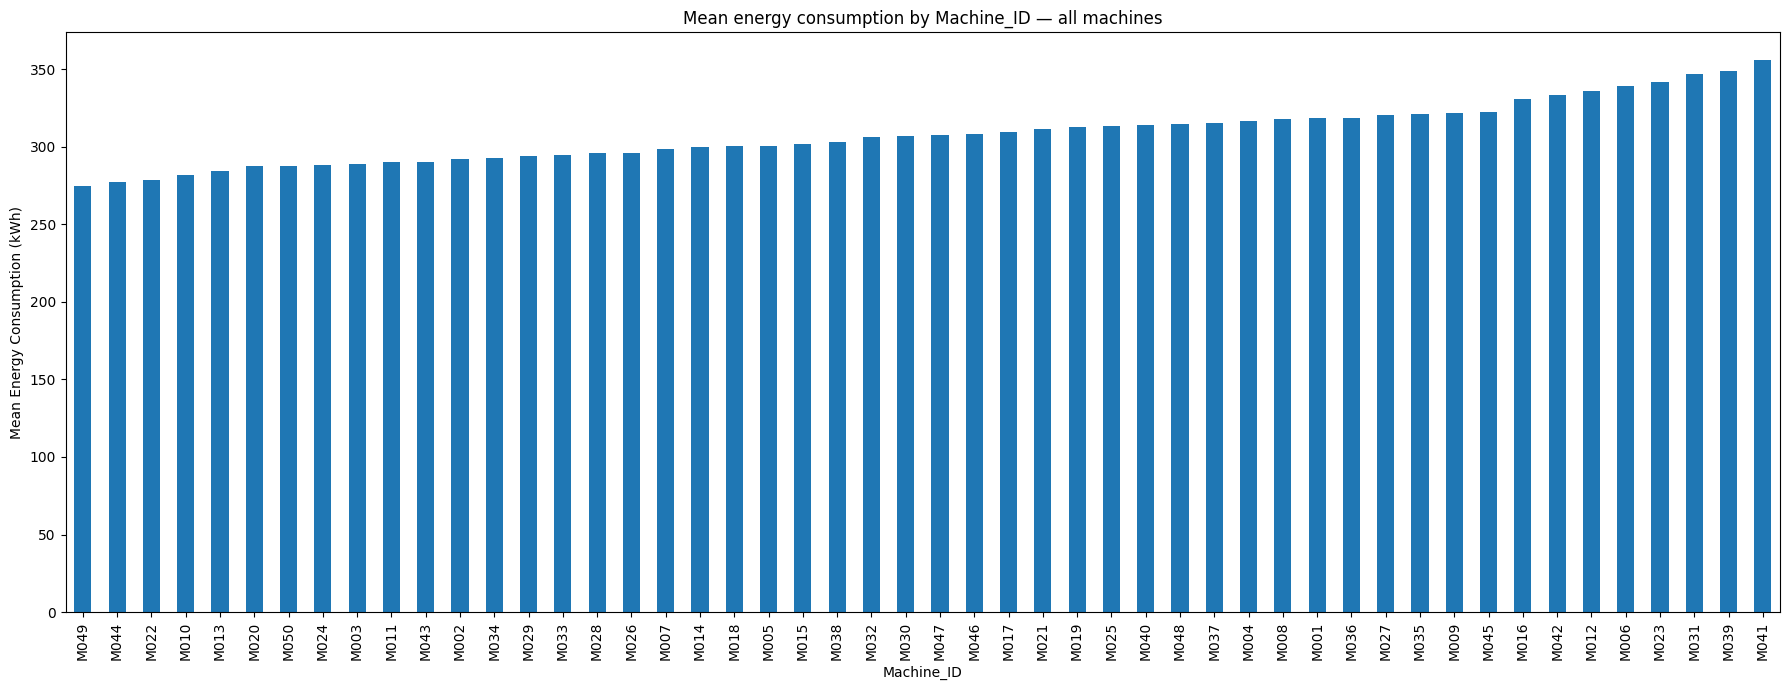


MACHINE METADATA CONSISTENCY — expected one type and one age per machine


,rows,machine_type_nunique,machine_age_nunique,machine_types,min_age_years,max_age_years
Machine_ID,,,,,,
M034,209,1,95,CNC_Grinder,1.550,2.550
M026,227,1,93,CNC_Mill,5.130,6.110
M038,216,1,92,CNC_Mill,4.820,5.810
M029,214,1,91,CNC_Mill,2.800,3.800
M030,207,1,91,CNC_Grinder,8.750,9.740
M039,206,1,91,Laser_Cutter,7.850,8.830
M040,219,1,91,CNC_Grinder,12.840,13.840
M008,222,1,90,CNC_Grinder,12.420,13.410
M022,180,1,90,CNC_Lathe,1.520,2.510


Machines with >1 Machine_Type: 0
Machines with >1 Machine_Age_years: 50

MONTHLY ENERGY AND AMBIENT TEMPERATURE


,Production_Month,n_energy,mean_energy_kWh,median_energy_kWh,mean_ambient_temperature_C
0,2025-01,806,349.580,342.040,8.334
1,2025-02,728,339.214,331.525,9.257
2,2025-03,829,317.150,309.380,12.190
3,2025-04,818,289.988,282.140,17.256
4,2025-05,764,282.850,273.820,22.262
5,2025-06,781,296.558,289.920,26.070
6,2025-07,834,307.674,302.960,27.972
7,2025-08,827,299.112,293.520,26.739
8,2025-09,762,286.815,278.875,23.519
9,2025-10,792,285.178,278.520,18.637


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_Monthly_Energy_and_Ambient_Temperature.png


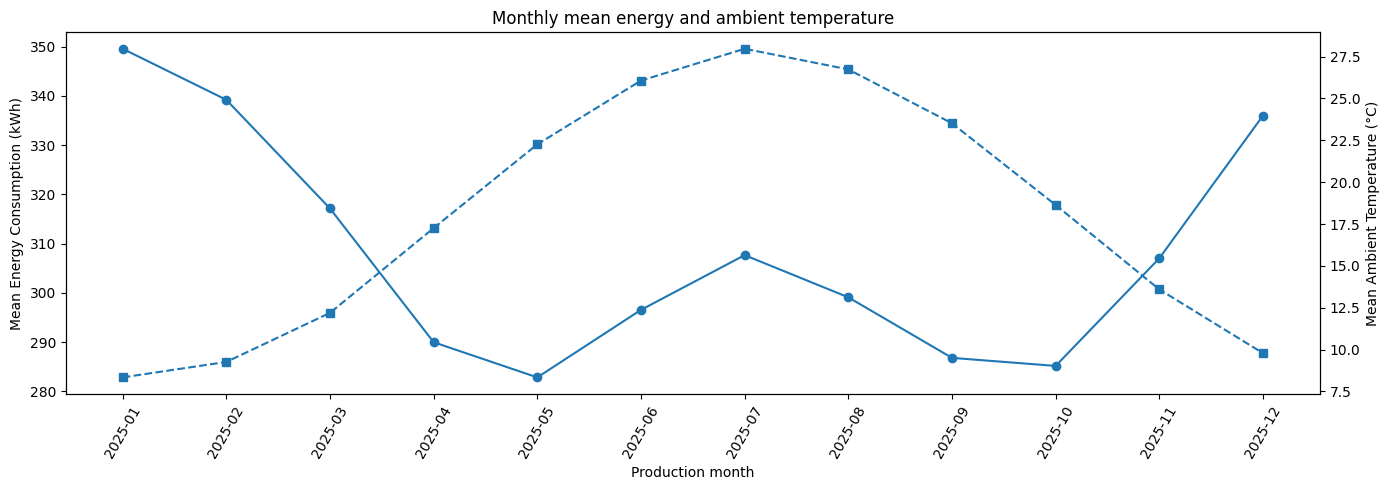


WEEKDAY MEANS


,n,mean_energy_kWh,median_energy_kWh,mean_ambient_temperature_C
Weekday,,,,
Monday,1329,311.443,304.330,17.992
Tuesday,1345,308.644,301.130,18.174
Wednesday,1415,308.054,301.560,18.147
Thursday,1377,304.593,300.070,17.962
Friday,1401,308.254,301.520,18.122
Saturday,1332,305.880,298.610,18.162
Sunday,1306,309.145,301.740,17.822


In [5]:
# Expanded integrity, missingness, limits, extremes, relationships, machine and calendar audit.
from scipy.stats import spearmanr
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("\nCLEANING SUMMARY")
print(pd.Series({
    "raw_csv_rows": len(df_raw),
    "canonical_rows_used": len(df_canonical),
    "appended_rows_excluded": len(df_appended_rows),
    "exact_duplicates_in_canonical_block": int(df_canonical.duplicated().sum()),
    "Tree_labels_corrected": int(tree_mask.sum()),
    "Dream_shifts_set_missing": int(dream_mask.sum()),
    "final_analysis_rows_retained": len(df),
    "extreme_values_set_missing": int(sum(extreme_audit_counts.values())),
}).to_frame("value"))

# Exact boundary/limit values requested for inspection.
limit_checks = {
    "Operating_Hours_per_Day": [6, 24],
    "Days_Since_Maintenance": [100],
    "Operator_Experience_years": [22],
    "Ambient_Temperature_C": [5],
}
limit_rows = []
for col, limits in limit_checks.items():
    for value in limits:
        limit_rows.append({"feature": col, "limit_value": value, "count": int((df[col] == value).sum()), "pct_of_clean_rows": float((df[col] == value).mean() * 100)})
limit_table = pd.DataFrame(limit_rows)
print("\nBOUNDARY VALUES")
display(limit_table.round(3))

# Missingness rate by machine type, machine ID, and month, alongside group size.
missing_features = [c for c in df.columns if df[c].isna().any()]
df["Production_Month"] = df[DATE_COL].dt.to_period("M").astype(str)
for group_col in ["Machine_Type", "Machine_ID", "Production_Month"]:
    rows = []
    for key, grp in df.groupby(group_col, dropna=False):
        row = {group_col: key, "n_rows": len(grp)}
        for col in missing_features:
            row[f"{col}_missing_pct"] = grp[col].isna().mean() * 100
        rows.append(row)
    miss_group = pd.DataFrame(rows)
    print(f"\nMISSINGNESS RATE BY {group_col}")
    display(miss_group.round(2))

# Mean energy for rows where each feature is missing versus observed.
missing_energy_rows = []
for col in missing_features:
    for is_missing, label in [(True, "missing"), (False, "observed")]:
        subset = df.loc[df[col].isna() == is_missing, TARGET]
        missing_energy_rows.append({"feature": col, "feature_status": label, "rows": int(len(subset)), "energy_mean_kWh": subset.mean(), "energy_median_kWh": subset.median()})
missing_energy_comparison = pd.DataFrame(missing_energy_rows)
print("\nENERGY MEAN WITH/WITHOUT EACH MISSING VALUE")
display(missing_energy_comparison.round(3))

# Explicit extreme groups: count, descriptive profile and complete top-15 high-energy table.
extreme_specs = {
    "Average_Machine_Temperature_C > 120": ("Average_Machine_Temperature_C", lambda s: s > 120),
    "Cycle_Time_sec > 200": ("Cycle_Time_sec", lambda s: s > 200),
    "Vibration_mm_s > 6": ("Vibration_mm_s", lambda s: s > 6),
    "Energy_Consumption_kWh > 800": (TARGET, lambda s: s > 800),
}
extreme_profiles = []
for label, (col, condition) in extreme_specs.items():
    mask = condition(df_pre_outlier[col]) & df_pre_outlier[col].notna()
    group = df_pre_outlier.loc[mask]
    extreme_profiles.append({
        "extreme_group": label, "rows": int(mask.sum()), "pct_of_clean_rows": float(mask.mean() * 100),
        "energy_mean_kWh": group[TARGET].mean(), "energy_median_kWh": group[TARGET].median(),
        "machine_types": ", ".join(group["Machine_Type"].value_counts().index.astype(str).tolist()),
        "machines": int(group["Machine_ID"].nunique()),
    })
    print(f"\n{label}: descriptive profile")
    display(group.describe(include="all").T)
extreme_profile_table = pd.DataFrame(extreme_profiles)
print("\nEXTREME-GROUP SUMMARY")
display(extreme_profile_table.round(3))

# Test a Fahrenheit interpretation of the high-temperature tail without assuming it is correct.
hot = df_pre_outlier.loc[df_pre_outlier["Average_Machine_Temperature_C"] > 120, [ID_COL, "Machine_ID", "Machine_Type", "Average_Machine_Temperature_C", TARGET]].copy()
hot["temperature_if_fahrenheit_converted_to_c"] = (hot["Average_Machine_Temperature_C"] - 32) * 5 / 9
print("\nTEMPERATURE >120: FAHRENHEIT-CONVERSION CHECK")
print("Raw high-temperature count:", len(hot))
display(hot.sort_values("Average_Machine_Temperature_C", ascending=False).head(25))
display(hot[["Average_Machine_Temperature_C", "temperature_if_fahrenheit_converted_to_c"]].describe().round(3))
print("Interpretation: the conversion is a diagnostic scenario only; units cannot be confirmed from the numeric values alone.")

# Full top-15 high-energy rows with all requested context columns.
top15_cols = [ID_COL, DATE_COL, "Machine_ID", "Machine_Type", "Shift", "Machine_Age_years",
              "Operating_Hours_per_Day", "Production_Volume_units", "Product_Complexity_Index",
              "Material_Hardness_HB", "Cycle_Time_sec", "Spindle_Load_pct",
              "Average_Machine_Temperature_C", "Vibration_mm_s", "Tool_Wear_Index",
              "Days_Since_Maintenance", "Operator_Experience_years", "Ambient_Temperature_C",
              "Humidity_pct", TARGET]
top15_energy = df_pre_outlier.nlargest(15, TARGET)[top15_cols]
print("\nTOP 15 HIGH-ENERGY ROWS — FULL TABLE")
display(top15_energy.reset_index(drop=True))

# Pearson and Spearman correlations. Also calculate Pearson correlations after excluding all four extreme groups.
correlation_cols = [c for c in df.select_dtypes(include=np.number).columns if c != ID_COL]
pearson_all = df[correlation_cols].corr(method="pearson")
spearman_all = df[correlation_cols].corr(method="spearman")
print("\nSPEARMAN CORRELATION MATRIX")
display(spearman_all.round(3))

extreme_any = (df_pre_outlier["Average_Machine_Temperature_C"].gt(120) | df_pre_outlier["Cycle_Time_sec"].gt(200) |
               df_pre_outlier["Vibration_mm_s"].gt(6) | df_pre_outlier[TARGET].gt(800))
df_no_extremes = df_pre_outlier.loc[~extreme_any].copy()
pearson_no_extremes = df_no_extremes[correlation_cols].corr(method="pearson")
print("\nPEARSON CORRELATIONS AFTER EXCLUDING ANY ROW IN AN EXTREME GROUP")
print(f"Rows retained after removing any row flagged by the four extreme rules: {len(df_no_extremes):,} of {len(df_pre_outlier):,}")
display(pearson_no_extremes.round(3))

# Annotated lower-triangle diverging heatmap (clean analysis copy).
corr_heat = df[correlation_cols].corr(method="pearson")
mask_upper = np.triu(np.ones_like(corr_heat, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(14, 11))
import seaborn as sns
sns.heatmap(corr_heat, mask=mask_upper, annot=True, fmt=".2f", cmap="vlag", center=0,
            square=True, linewidths=0.35, cbar_kws={"shrink": 0.75}, ax=ax, annot_kws={"size": 7})
ax.set_title("Pearson correlations — lower triangle")
plt.tight_layout()
save_and_show("Figure_12_Pearson_Correlation_Lower_Triangle.png")

# VIF on complete cases and predictors excluding identifiers and target. This is a diagnostic only.
vif_predictors = [c for c in correlation_cols if c != TARGET]
vif_data = df[vif_predictors].dropna().copy()
# Drop constant columns if any, as VIF is undefined for constants.
vif_data = vif_data.loc[:, vif_data.nunique(dropna=True) > 1]
vif_rows = []
if len(vif_data) > len(vif_data.columns) + 1:
    from statsmodels.tools.tools import add_constant
    vif_matrix = add_constant(vif_data, has_constant="add")
    for i, col in enumerate(vif_matrix.columns):
        if col == "const":
            continue
        vif_rows.append({"feature": col, "VIF": variance_inflation_factor(vif_matrix.to_numpy(), i)})
vif_table = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False)
print("\nVARIANCE INFLATION FACTORS (complete cases; not a causal test)")
display(vif_table.round(3))

# Binned means for specified variables and finer cycle-time bins below 60 seconds.
requested_bin_specs = {
    "Ambient_Temperature_C": [5, 10, 15, 20, 25, 30, 35, 40],
    "Humidity_pct": [0, 20, 30, 40, 50, 60, 70, 80, 100],
    "Material_Hardness_HB": [100, 150, 200, 250, 300, 350, 400],
    "Tool_Wear_Index": [0, .1, .2, .3, .4, .5, .6, .7, .8, .9, 1.0],
    "Vibration_mm_s": [0, 1, 2, 3, 4, 5, 6, 8, 12],
    "Product_Complexity_Index": [0, 2, 3, 4, 5, 6, 7, 8, 10],
    "Cycle_Time_sec": [0, 10, 20, 30, 40, 50, 60, 80, 100, 120, 160, 220, 400],
}
for col, edges in requested_bin_specs.items():
    tmp = df[[col, TARGET]].dropna().copy()
    tmp["bin"] = pd.cut(tmp[col], bins=edges, include_lowest=True, right=True)
    summary = tmp.groupby("bin", observed=False)[TARGET].agg(["count", "mean", "median", "std"]).reset_index()
    print(f"\nBINNED ENERGY SUMMARY: {col}")
    display(summary.round(3))

# Two requested interaction tables.
df["Spindle_Load_Band"] = pd.cut(df["Spindle_Load_pct"], bins=[0, 40, 60, 75, 90, 100], include_lowest=True)
df["Complexity_Band"] = pd.cut(df["Product_Complexity_Index"], bins=[0, 2, 4, 6, 8, 10], include_lowest=True)
spindle_complexity = df.pivot_table(index="Spindle_Load_Band", columns="Complexity_Band", values=TARGET, aggfunc=["count", "mean", "median"], observed=False)
print("\nINTERACTION TABLE: SPINDLE LOAD × PRODUCT COMPLEXITY")
display(spindle_complexity.round(2))
df["Maintenance_Delay_Band"] = pd.cut(df["Days_Since_Maintenance"], bins=[0, 15, 30, 45, 60, 80, 100], include_lowest=True)
df["Tool_Wear_Band"] = pd.cut(df["Tool_Wear_Index"], bins=[0, .2, .4, .6, .8, 1.0], include_lowest=True)
maintenance_wear = df.pivot_table(index="Maintenance_Delay_Band", columns="Tool_Wear_Band", values=TARGET, aggfunc=["count", "mean", "median"], observed=False)
print("\nINTERACTION TABLE: DAYS SINCE MAINTENANCE × TOOL WEAR")
display(maintenance_wear.round(2))

# Machine-level target summaries and validation of machine metadata consistency.
energy_by_machine = df.groupby("Machine_ID")[TARGET].agg(n="count", mean="mean", median="median", std="std").sort_values("mean", ascending=False)
print("\nENERGY BY MACHINE_ID — ALL MACHINES, SORTED BY MEAN ENERGY")
display(energy_by_machine.round(3))
fig, ax = plt.subplots(figsize=(18, 7))
energy_by_machine["mean"].sort_values().plot(kind="bar", ax=ax)
ax.set_title("Mean energy consumption by Machine_ID — all machines")
ax.set_xlabel("Machine_ID")
ax.set_ylabel("Mean Energy Consumption (kWh)")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
save_and_show("Figure_Mean_Energy_by_All_50_Machines.png")
metadata_consistency = df.groupby("Machine_ID").agg(
    rows=(ID_COL, "size"), machine_type_nunique=("Machine_Type", "nunique"),
    machine_age_nunique=("Machine_Age_years", "nunique"),
    machine_types=("Machine_Type", lambda s: ", ".join(sorted(s.dropna().astype(str).unique()))),
    min_age_years=("Machine_Age_years", "min"), max_age_years=("Machine_Age_years", "max")
).sort_values(["machine_type_nunique", "machine_age_nunique"], ascending=False)
print("\nMACHINE METADATA CONSISTENCY — expected one type and one age per machine")
display(metadata_consistency.round(3))
print("Machines with >1 Machine_Type:", int((metadata_consistency["machine_type_nunique"] > 1).sum()))
print("Machines with >1 Machine_Age_years:", int((metadata_consistency["machine_age_nunique"] > 1).sum()))

# Monthly energy and ambient-temperature means side by side, plus weekday means.
df["Weekday"] = df[DATE_COL].dt.day_name()
monthly_summary = df.groupby("Production_Month").agg(
    n_energy=(TARGET, "count"), mean_energy_kWh=(TARGET, "mean"), median_energy_kWh=(TARGET, "median"),
    mean_ambient_temperature_C=("Ambient_Temperature_C", "mean")
).reset_index()
print("\nMONTHLY ENERGY AND AMBIENT TEMPERATURE")
display(monthly_summary.round(3))
fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(monthly_summary["Production_Month"], monthly_summary["mean_energy_kWh"], marker="o", label="Mean energy (kWh)")
ax1.set_ylabel("Mean Energy Consumption (kWh)")
ax1.set_xlabel("Production month")
ax2 = ax1.twinx()
ax2.plot(monthly_summary["Production_Month"], monthly_summary["mean_ambient_temperature_C"], marker="s", linestyle="--", label="Mean ambient temperature (°C)")
ax2.set_ylabel("Mean Ambient Temperature (°C)")
ax1.tick_params(axis="x", rotation=60)
ax1.set_title("Monthly mean energy and ambient temperature")
plt.tight_layout()
save_and_show("Figure_Monthly_Energy_and_Ambient_Temperature.png")
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = df.groupby("Weekday").agg(n=(TARGET, "count"), mean_energy_kWh=(TARGET, "mean"), median_energy_kWh=(TARGET, "median"), mean_ambient_temperature_C=("Ambient_Temperature_C", "mean")).reindex(weekday_order)
print("\nWEEKDAY MEANS")
display(weekday_summary.round(3))


### Initial data-quality interpretation

The CSV contains 10,250 rows, but the first 10,000 records have unique `Observation_ID` values 1–10,000. The remaining 250 rows restart the ID sequence; 228 are exact copies and 22 are non-identical twins. The notebook therefore uses the first 10,000 rows as the provisional canonical dataset and excludes the appended tail from the primary analysis. This boundary should be confirmed with the data owner.

Five `Tree` labels were corrected using the type associated with each machine elsewhere in the canonical block. Five `Dream` shifts were retained as records but set to missing. Extreme values above the stated thresholds are set to missing only in the analytical copy, while their original values remain available for audit. The suspected-error interpretation needs lecturer/data-owner confirmation; the CSV alone does not prove the cause of every extreme.


# 3. Exploratory Data Analysis

## 3.1 Dimension of the dataset and basic statistical features

This section directly addresses the grading criterion for dataset dimensions and statistical characteristics.


In [6]:
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("\nNumeric columns:", len(numeric_cols))
print("Categorical/text columns:", len(categorical_cols))

display(df[numeric_cols].describe().T)


Shape: (10000, 26)
Rows: 10000
Columns: 26

Numeric columns: 16
Categorical/text columns: 5


,count,mean,std,min,25%,50%,75%,max
Observation_ID,"10,000.000","5,000.500","2,886.896",1.000,"2,500.750","5,000.500","7,500.250","10,000.000"
Machine_Age_years,"10,000.000",8.167,3.929,1.470,4.848,7.910,12.400,14.740
Operating_Hours_per_Day,"10,000.000",15.952,3.574,6.000,13.530,15.990,18.470,24.000
Production_Volume_units,"10,000.000",532.871,182.849,127.000,405.000,507.000,629.000,"1,800.000"
Product_Complexity_Index,"10,000.000",5.385,1.954,1.040,3.850,5.350,6.900,9.960
Material_Hardness_HB,"10,000.000",253.116,33.491,131.800,230.100,252.700,275.900,360.000
Cycle_Time_sec,"9,899.000",87.766,18.012,26.630,75.055,87.510,100.340,145.000
Spindle_Load_pct,"10,000.000",65.734,11.599,28.900,57.500,65.650,73.940,98.000
Average_Machine_Temperature_C,"9,506.000",74.011,5.348,54.340,70.380,74.005,77.550,93.800
Vibration_mm_s,"9,408.000",2.410,0.575,0.648,1.992,2.408,2.808,4.400


### 3.2 Feature inventory aligned with the project scenario

The project brief groups the predictors conceptually into production, machine-condition, maintenance, human, and environmental factors. The table below preserves the supplied feature names while assigning an analytical role for EDA.

| Project role | Variables examined |
|---|---|
| Identifier / calendar | `Observation_ID`, `Production_Date`, `Machine_ID` |
| Machine configuration | `Machine_Type`, `Shift` |
| Production | `Operating_Hours_per_Day`, `Production_Volume_units`, `Product_Complexity_Index`, `Material_Hardness_HB`, `Cycle_Time_sec`, `Spindle_Load_pct` |
| Machine condition | `Average_Machine_Temperature_C`, `Vibration_mm_s`, `Tool_Wear_Index` |
| Maintenance | `Days_Since_Maintenance` |
| Human factor | `Operator_Experience_years` |
| Environment | `Ambient_Temperature_C`, `Humidity_pct` |
| Target | `Energy_Consumption_kWh` |

The use-case image (Figure 1) motivates this grouping: machine settings, production volume, equipment condition/maintenance, environmental conditions, and energy consumption are explicitly highlighted.


## 4. Data types and missing-value detection

Missing values are not imputed in this EDA. Imputation would be a modeling/data-preparation decision and could change distributions. Instead, missingness is quantified and its possible analytical implications are recorded.

For predictive work, missing-value handling should be performed inside a reproducible preprocessing workflow rather than by silently replacing values during EDA.


In [7]:
dtype_table = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100).round(2),
    "unique_values": df.nunique(dropna=True)
}).sort_values(["missing_pct", "data_type"], ascending=[False, True])

display(dtype_table)


,data_type,non_null,missing,missing_pct,unique_values
Tool_Wear_Band,category,9400,600,6.000,5
Tool_Wear_Index,float64,9400,600,6.000,860
Vibration_mm_s,float64,9408,592,5.920,2432
Energy_Consumption_kWh,float64,9505,495,4.950,7820
Average_Machine_Temperature_C,float64,9506,494,4.940,2343
Humidity_pct,float64,9700,300,3.000,3735
Cycle_Time_sec,float64,9899,101,1.010,5306
Shift,object,9995,5,0.050,3
Spindle_Load_Band,category,10000,0,0.000,5
Complexity_Band,category,10000,0,0.000,5


,missing_count,missing_pct
Tool_Wear_Band,600,6.000
Tool_Wear_Index,600,6.000
Vibration_mm_s,592,5.920
Energy_Consumption_kWh,495,4.950
Average_Machine_Temperature_C,494,4.940
Humidity_pct,300,3.000
Cycle_Time_sec,101,1.010
Shift,5,0.050


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_02_Missing_Value_Rate_by_Feature.png


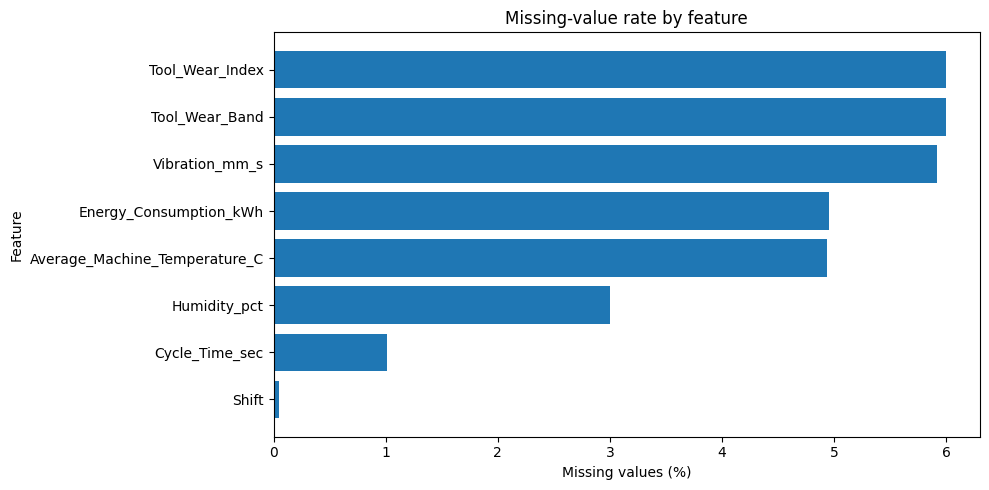

In [8]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct
})
display(missing_table[missing_table["missing_count"] > 0])

plt.figure(figsize=(10, 5))
m = missing_table[missing_table["missing_count"] > 0].sort_values("missing_count")
plt.barh(m.index, m["missing_pct"])
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Missing-value rate by feature")
plt.tight_layout()
save_and_show("Figure_02_Missing_Value_Rate_by_Feature.png")


**Figure 2 interpretation.** Missingness is concentrated in `Tool_Wear_Index`, `Vibration_mm_s`, `Average_Machine_Temperature_C`, `Energy_Consumption_kWh`, and `Humidity_pct`. The target itself contains missing values, so rows with an unknown target cannot be used for supervised regression training without a dedicated treatment. For EDA, target-related plots use only rows where the target is observed.

The missingness pattern is a data-quality finding, not evidence that missing observations should be replaced with a particular statistic.


# 5. Analysis of categorical variables

The project rubric explicitly requests categorical analysis using plots such as bar charts and pie charts. We analyze the operational categories while avoiding an unreadable 50-category pie chart for `Machine_ID`.


In [9]:
cat_summary = {}
for col in ["Machine_Type", "Shift", "Machine_ID"]:
    vc = df[col].value_counts(dropna=False)
    cat_summary[col] = pd.DataFrame({
        "count": vc,
        "percentage": (vc / len(df) * 100).round(2)
    })
    print(f"\n{col}")
    display(cat_summary[col].head(20))



Machine_Type


,count,percentage
Machine_Type,,
CNC_Mill,3606,36.060
CNC_Grinder,2236,22.360
CNC_Lathe,2208,22.080
Laser_Cutter,1950,19.500



Shift


,count,percentage
Shift,,
Day,5071,50.710
Evening,2862,28.620
Night,2062,20.620
NaN,5,0.050



Machine_ID


,count,percentage
Machine_ID,,
M026,227,2.270
M009,227,2.270
M014,222,2.220
M008,222,2.220
M043,219,2.190
M040,219,2.190
M038,216,2.160
M029,214,2.140
M003,213,2.130


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_03_04_Machine_Type_and_Shift_Distribution.png


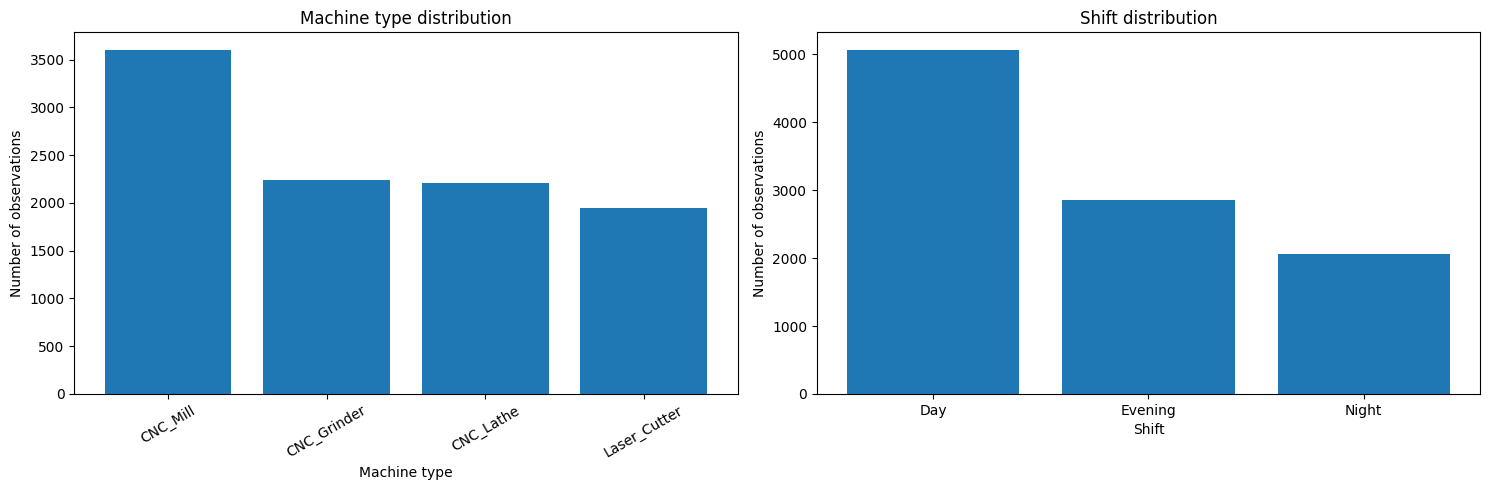

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
machine_type_counts = df["Machine_Type"].value_counts()
axes[0].bar(machine_type_counts.index, machine_type_counts.values)
axes[0].set_title("Machine type distribution")
axes[0].set_xlabel("Machine type")
axes[0].set_ylabel("Number of observations")
axes[0].tick_params(axis="x", rotation=30)
shift_counts = df["Shift"].value_counts()
axes[1].bar(shift_counts.index, shift_counts.values)
axes[1].set_title("Shift distribution")
axes[1].set_xlabel("Shift")
axes[1].set_ylabel("Number of observations")
plt.tight_layout()
save_and_show("Figure_03_04_Machine_Type_and_Shift_Distribution.png")

Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_05_06_Machine_Type_and_Shift_Share.png


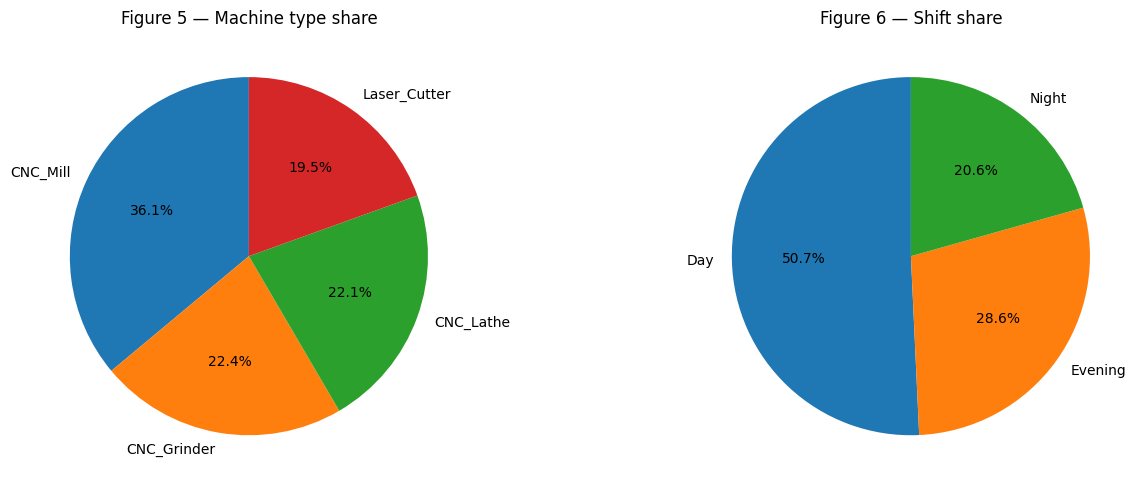

Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_07_Top_15_Machine_ID_Frequencies.png


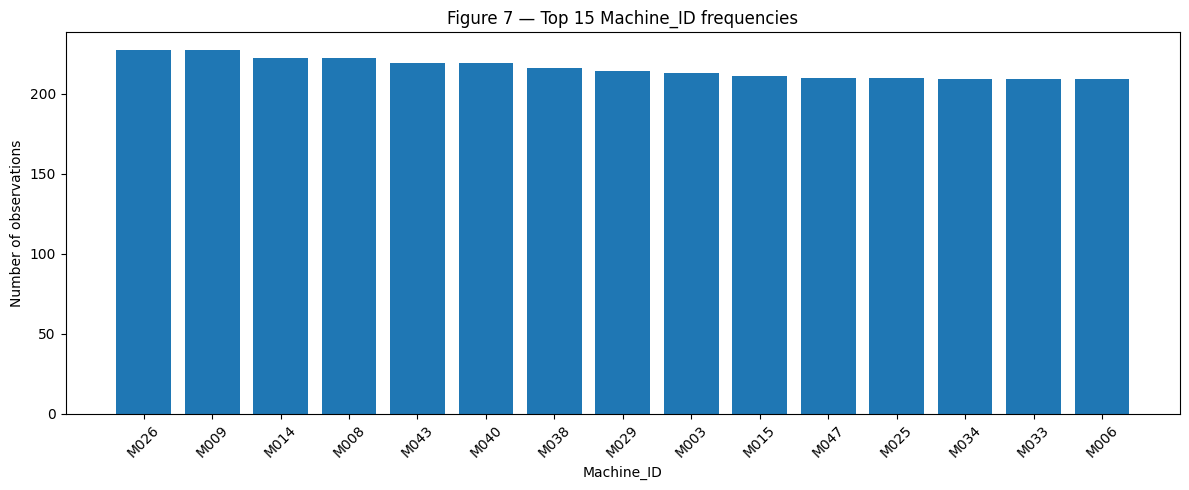

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].pie(
    machine_type_counts.values,
    labels=machine_type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0].set_title("Figure 5 — Machine type share")

axes[1].pie(
    shift_counts.values,
    labels=shift_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Figure 6 — Shift share")

plt.tight_layout()
save_and_show("Figure_05_06_Machine_Type_and_Shift_Share.png")

# Top 15 machine IDs for a readable categorical diagnostic.
top_machine_ids = df["Machine_ID"].value_counts().head(15)
plt.figure(figsize=(12, 5))
plt.bar(top_machine_ids.index, top_machine_ids.values)
plt.title("Figure 7 — Top 15 Machine_ID frequencies")
plt.xlabel("Machine_ID")
plt.ylabel("Number of observations")
plt.xticks(rotation=45)
plt.tight_layout()
save_and_show("Figure_07_Top_15_Machine_ID_Frequencies.png")

### Categorical findings

- `Machine_ID` contains many levels, so a full pie chart would be inappropriate; a frequency table and top-15 bar chart provide a more readable diagnostic.
- The supplied project description expects four machine types and three shifts. The raw file contains five observations with `Machine_Type = "Tree"` and five with `Shift = "Dream"`. These ten rows are excluded from the analysis copy and listed in the integrity audit; `df_raw` remains unchanged.
- The distribution of observations across machine types and shifts should be considered when comparing group-level energy consumption because the groups are not equally sized.


# 6. Analysis of numerical variables

The rubric requests box plots, violin plots, histograms, and distribution/KDE plots. Because the dataset contains many numeric variables, the notebook uses a complete numeric overview plus focused target-oriented visualizations.

`Observation_ID` is excluded from substantive numerical analysis because the project brief defines it as an identifier.


In [11]:
analysis_numeric_cols = [c for c in numeric_cols if c != ID_COL]

# Descriptive statistics with skewness for numerical EDA.
numeric_profile = df[analysis_numeric_cols].describe().T
numeric_profile["missing"] = df[analysis_numeric_cols].isna().sum()
numeric_profile["missing_pct"] = df[analysis_numeric_cols].isna().mean().mul(100)
numeric_profile["skewness"] = df[analysis_numeric_cols].skew(numeric_only=True)
display(numeric_profile.sort_index().style.format(precision=3))
print("Skewness by numeric feature (explicit full-width table):")
display(numeric_profile[["skewness"]].sort_values("skewness", ascending=False).round(3))


,count,mean,std,min,25%,50%,75%,max,missing,missing_pct,skewness
Ambient_Temperature_C,10000.000,18.057,7.634,5.000,11.308,18.010,24.690,37.110,0,0.000,0.035
Average_Machine_Temperature_C,9506.000,74.011,5.348,54.340,70.380,74.005,77.550,93.800,494,4.940,0.038
Cycle_Time_sec,9899.000,87.766,18.012,26.630,75.055,87.510,100.340,145.000,101,1.010,0.019
Days_Since_Maintenance,10000.000,33.410,20.783,0.500,18.000,29.200,44.600,100.000,0,0.000,1.018
Energy_Consumption_kWh,9505.000,307.985,67.513,134.940,260.010,301.210,348.180,704.930,495,4.950,0.643
Humidity_pct,9700.000,59.862,10.145,25.000,52.860,59.815,66.940,90.000,300,3.000,-0.008
Machine_Age_years,10000.000,8.167,3.929,1.470,4.848,7.910,12.400,14.740,0,0.000,0.066
Material_Hardness_HB,10000.000,253.116,33.491,131.800,230.100,252.700,275.900,360.000,0,0.000,0.037
Operating_Hours_per_Day,10000.000,15.952,3.574,6.000,13.530,15.990,18.470,24.000,0,0.000,-0.083
Operator_Experience_years,10000.000,6.228,4.222,0.200,3.070,5.270,8.360,22.000,0,0.000,1.163


Skewness by numeric feature (explicit full-width table):


,skewness
Operator_Experience_years,1.163
Production_Volume_units,1.076
Days_Since_Maintenance,1.018
Energy_Consumption_kWh,0.643
Tool_Wear_Index,0.498
Machine_Age_years,0.066
Product_Complexity_Index,0.054
Vibration_mm_s,0.053
Average_Machine_Temperature_C,0.038
Material_Hardness_HB,0.037


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_08_Numerical_Variable_Distributions_with_KDE.png


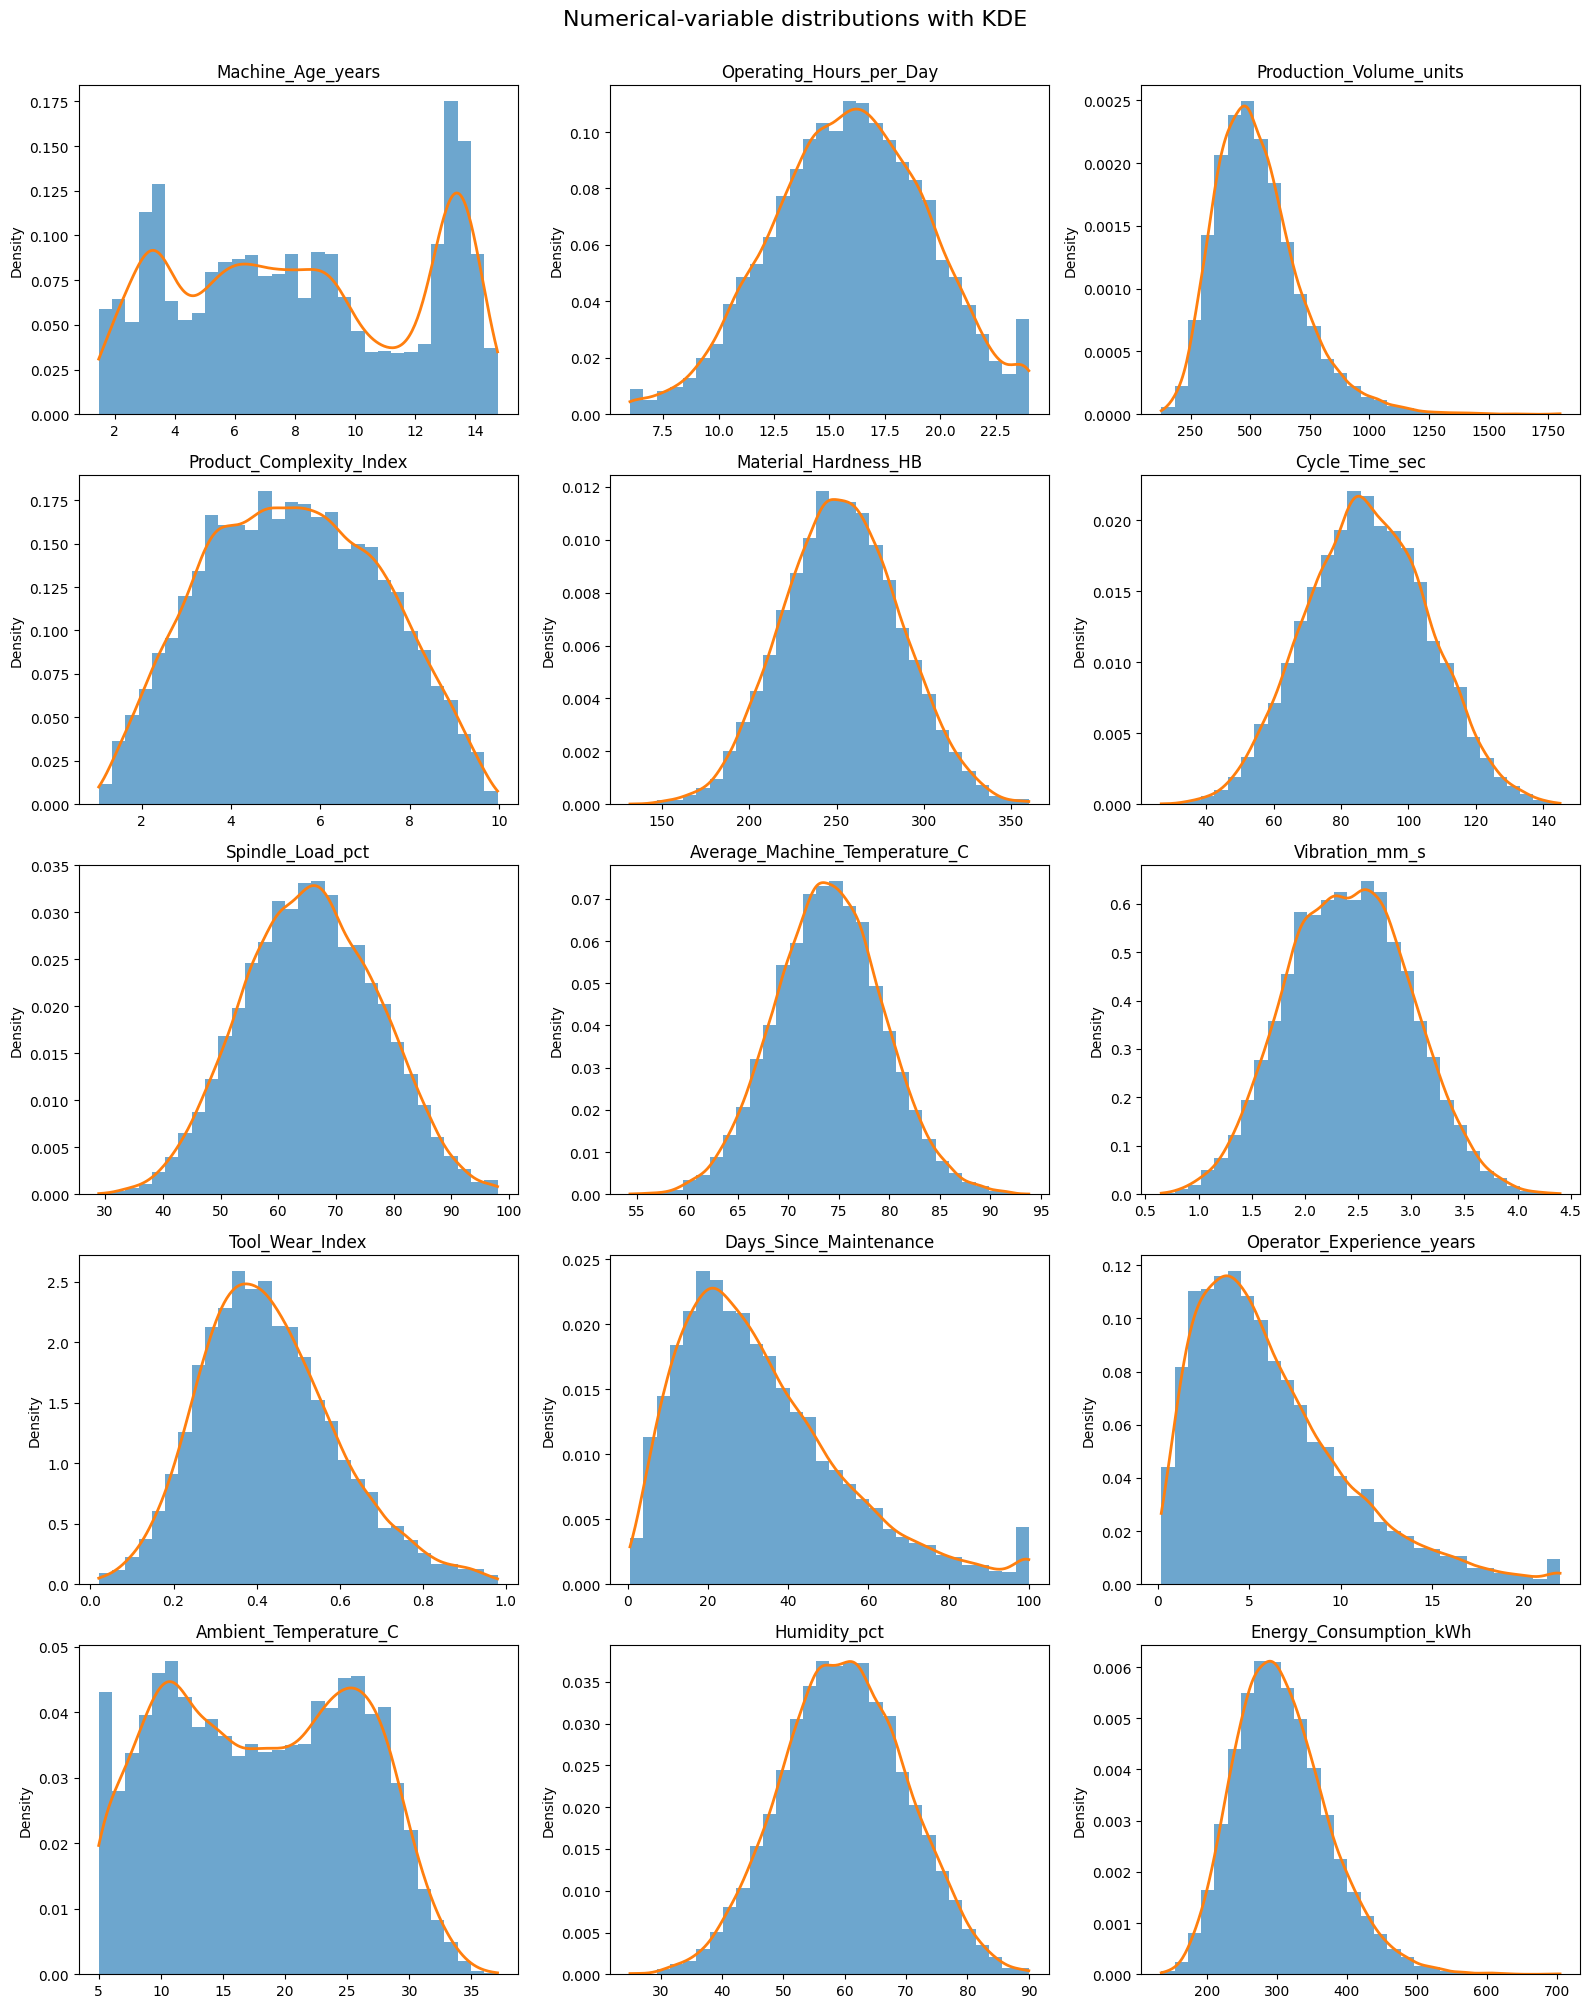

In [12]:
# Histograms + KDE for all numeric analytical variables.
from scipy.stats import gaussian_kde

ncols = 3
nrows = math.ceil(len(analysis_numeric_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.0 * nrows))
axes = np.asarray(axes).ravel()

for ax, col in zip(axes, analysis_numeric_cols):
    values = df[col].dropna().to_numpy()
    ax.hist(values, bins=30, alpha=0.65, density=True)
    if len(values) > 10 and np.nanstd(values) > 0:
        x_grid = np.linspace(values.min(), values.max(), 300)
        kde = gaussian_kde(values)
        ax.plot(x_grid, kde(x_grid), linewidth=2)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Density")

for ax in axes[len(analysis_numeric_cols):]:
    ax.remove()

fig.suptitle("Numerical-variable distributions with KDE", y=1.002, fontsize=16)
plt.tight_layout()
save_and_show("Figure_08_Numerical_Variable_Distributions_with_KDE.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_09_Numerical_Variable_Box_Plots.png


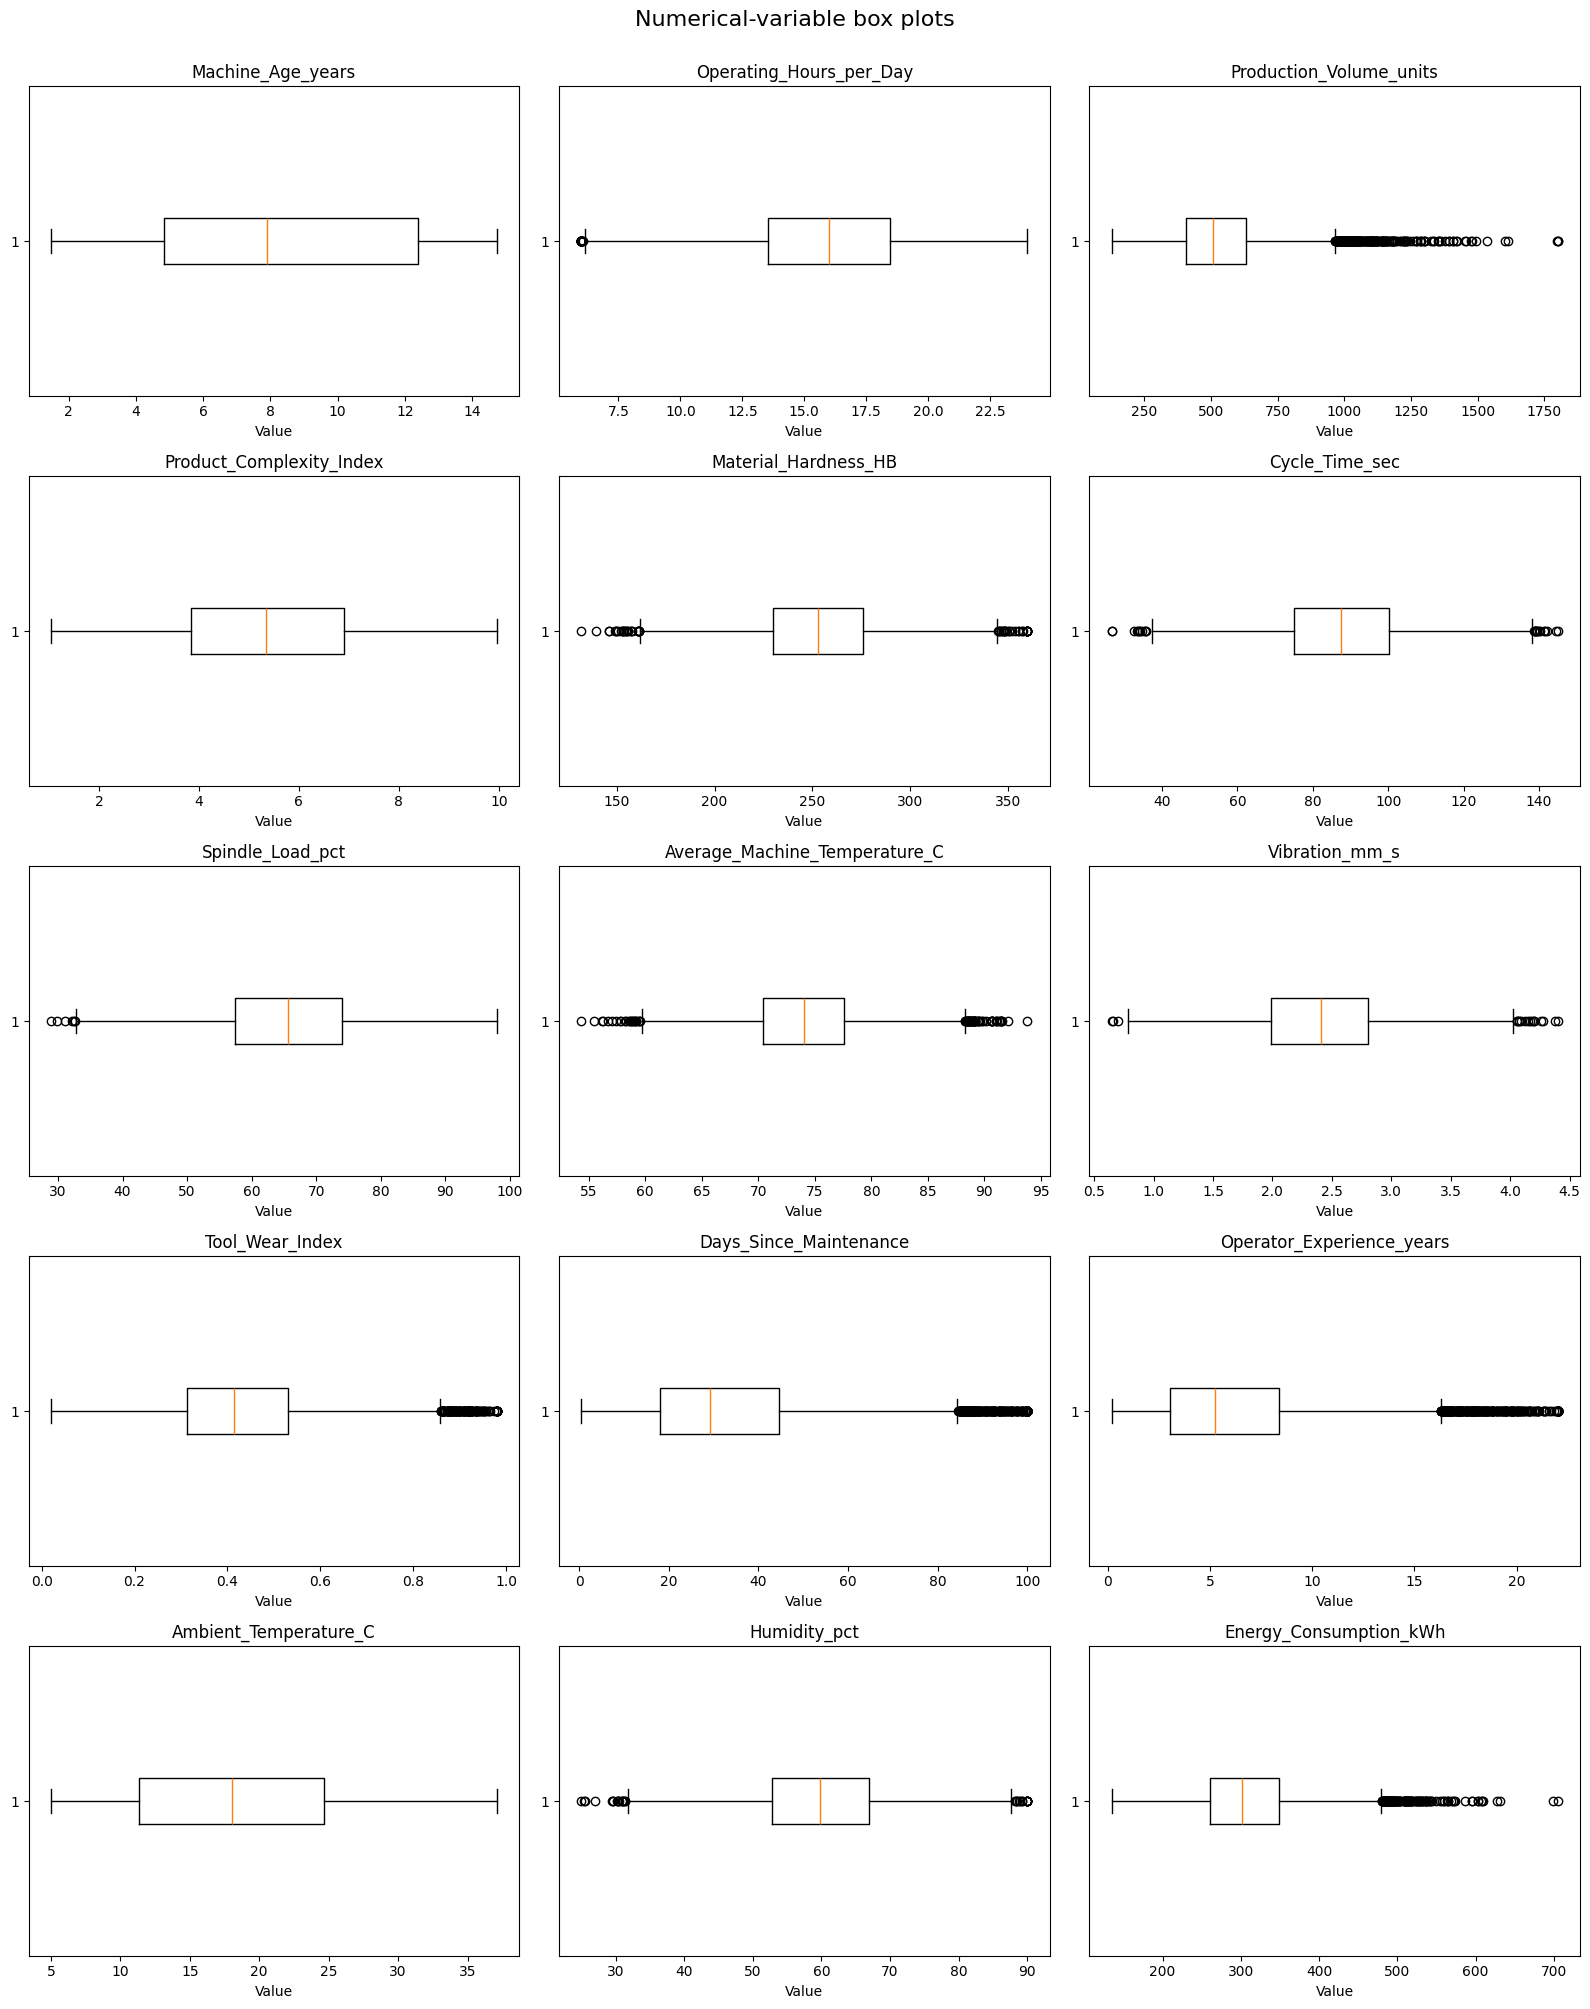

In [13]:
# Box plots for all numerical variables using independent panels.
ncols = 3
nrows = math.ceil(len(analysis_numeric_cols) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.0 * nrows))
axes = np.asarray(axes).ravel()

for ax, col in zip(axes, analysis_numeric_cols):
    values = df[col].dropna().to_numpy()
    ax.boxplot(values, vert=False)
    ax.set_title(col)
    ax.set_xlabel("Value")

for ax in axes[len(analysis_numeric_cols):]:
    ax.remove()

fig.suptitle("Numerical-variable box plots", y=1.002, fontsize=16)
plt.tight_layout()
save_and_show("Figure_09_Numerical_Variable_Box_Plots.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_10_Violin_Plots_Scenario_Critical_Variables.png


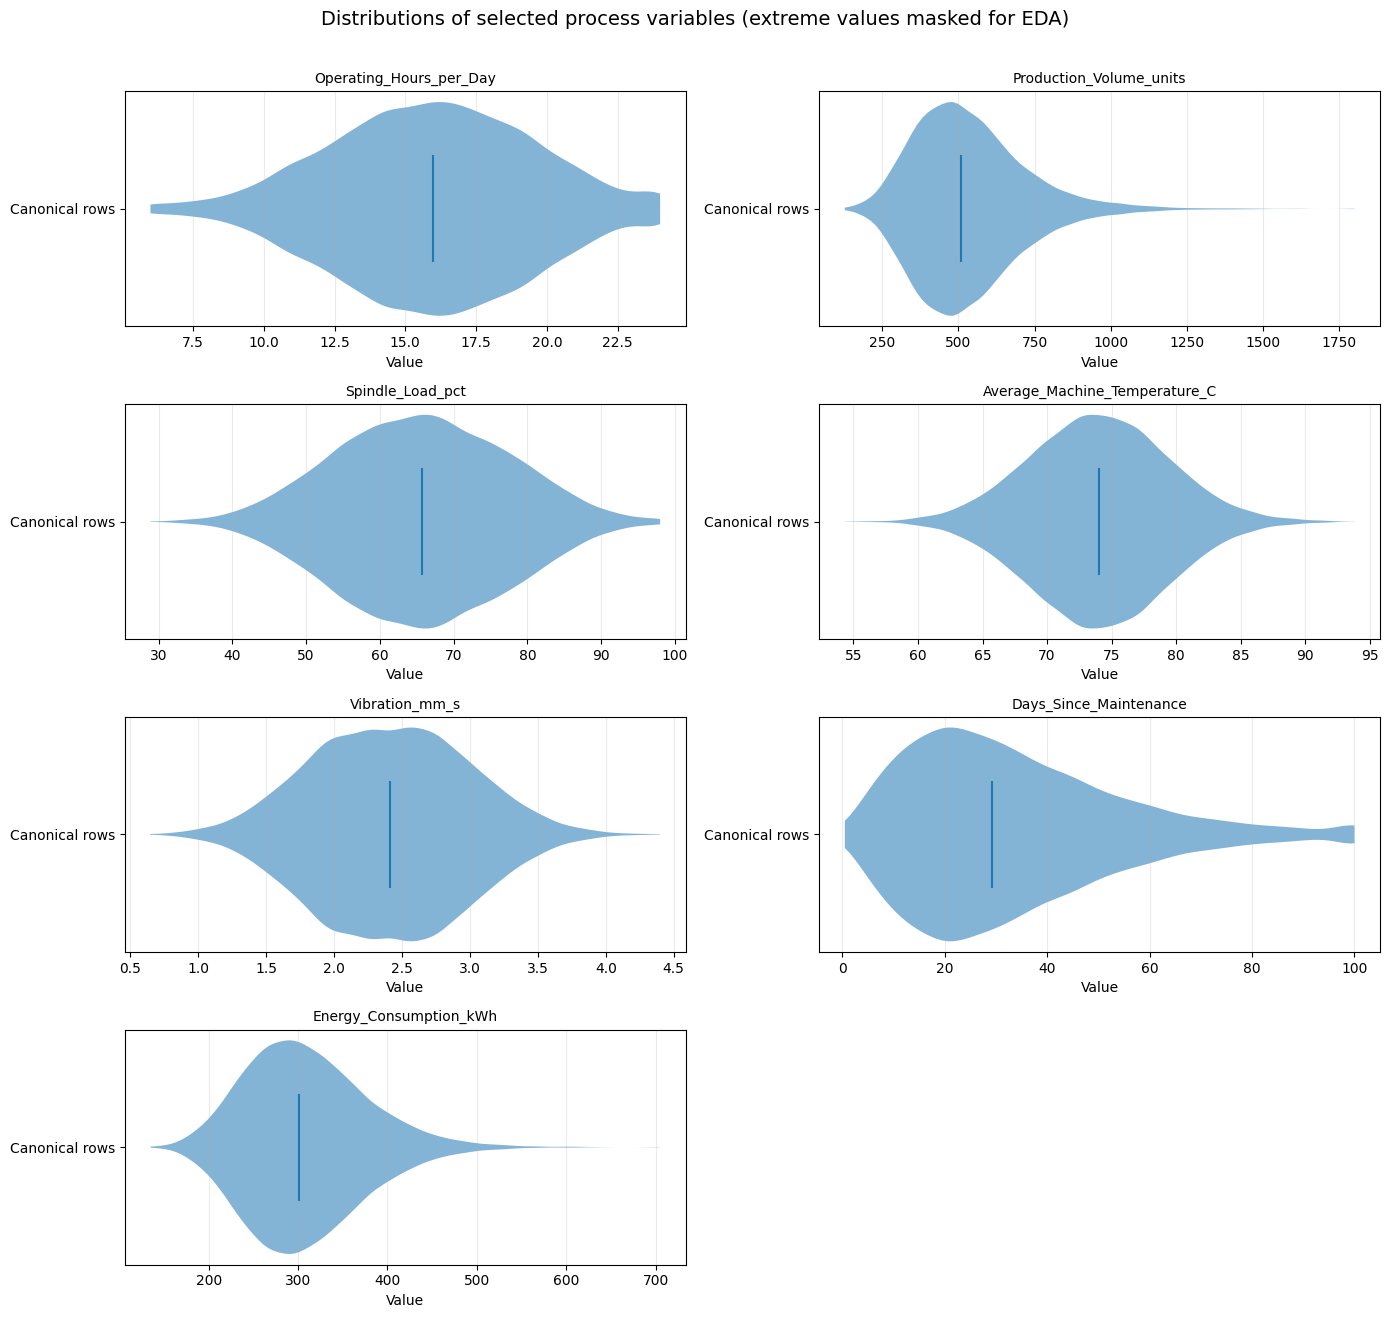

In [14]:
# Readable horizontal violin small multiples; extreme thresholds have been masked in df.
violin_cols = [
    "Operating_Hours_per_Day", "Production_Volume_units", "Spindle_Load_pct",
    "Average_Machine_Temperature_C", "Vibration_mm_s",
    "Days_Since_Maintenance", TARGET
]
fig, axes = plt.subplots(4, 2, figsize=(14, 13))
axes = axes.ravel()
for ax, col in zip(axes, violin_cols):
    values = df[col].dropna().to_numpy()
    if len(values):
        parts = ax.violinplot(values, vert=False, showmedians=True, showextrema=False, widths=0.7)
        for body in parts["bodies"]:
            body.set_alpha(0.55)
        ax.set_yticks([1])
        ax.set_yticklabels(["Canonical rows"])
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("Value")
    ax.grid(axis="x", alpha=0.25)
for ax in axes[len(violin_cols):]:
    ax.remove()
fig.suptitle("Distributions of selected process variables (extreme values masked for EDA)", y=1.01, fontsize=14)
plt.tight_layout()
save_and_show("Figure_10_Violin_Plots_Scenario_Critical_Variables.png")


### Numerical distribution observations

The numerical plots should be read together rather than independently. In particular:

1. The target and several process variables show non-normal or heavy-tailed behavior.
2. `Average_Machine_Temperature_C`, `Cycle_Time_sec`, `Production_Volume_units`, `Operator_Experience_years`, and other variables exhibit visible tail behavior that merits investigation.
3. The project brief explicitly warns about nonlinear behavior. Therefore, a simple Pearson correlation or a linear trend alone should not be treated as a complete description of the data-generating relationships.


# 7. Outlier detection

The project rubric explicitly assigns marks to outlier detection. We use the **1.5 × IQR rule** as a transparent screening method and report the number and percentage of observations beyond the inner fences.

This is an **outlier flag**, not an automatic deletion rule. NIST emphasizes that unusual observations should be investigated because they may represent either data problems or meaningful process behavior.


In [15]:
outlier_records = []

for col in analysis_numeric_cols:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)

    outlier_records.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_fence": lower,
        "upper_fence": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct": float(mask.mean() * 100)
    })

outlier_table = pd.DataFrame(outlier_records).sort_values(
    "outlier_count", ascending=False
).reset_index(drop=True)

display(outlier_table.round(3))


,feature,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_pct
0,Operator_Experience_years,3.070,8.360,5.290,-4.865,16.295,316,3.160
1,Days_Since_Maintenance,18.000,44.600,26.600,-21.900,84.500,299,2.990
2,Production_Volume_units,405.000,629.000,224.000,69.000,965.000,254,2.540
3,Tool_Wear_Index,0.313,0.531,0.218,-0.014,0.858,141,1.500
4,Energy_Consumption_kWh,260.010,348.180,88.170,127.755,480.435,139,1.462
5,Average_Machine_Temperature_C,70.380,77.550,7.170,59.625,88.305,75,0.789
6,Material_Hardness_HB,230.100,275.900,45.800,161.400,344.600,54,0.540
7,Operating_Hours_per_Day,13.530,18.470,4.940,6.120,25.880,41,0.410
8,Humidity_pct,52.860,66.940,14.080,31.740,88.060,33,0.340
9,Cycle_Time_sec,75.055,100.340,25.285,37.128,138.267,25,0.253


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_11_IQR_Based_Outlier_Counts.png


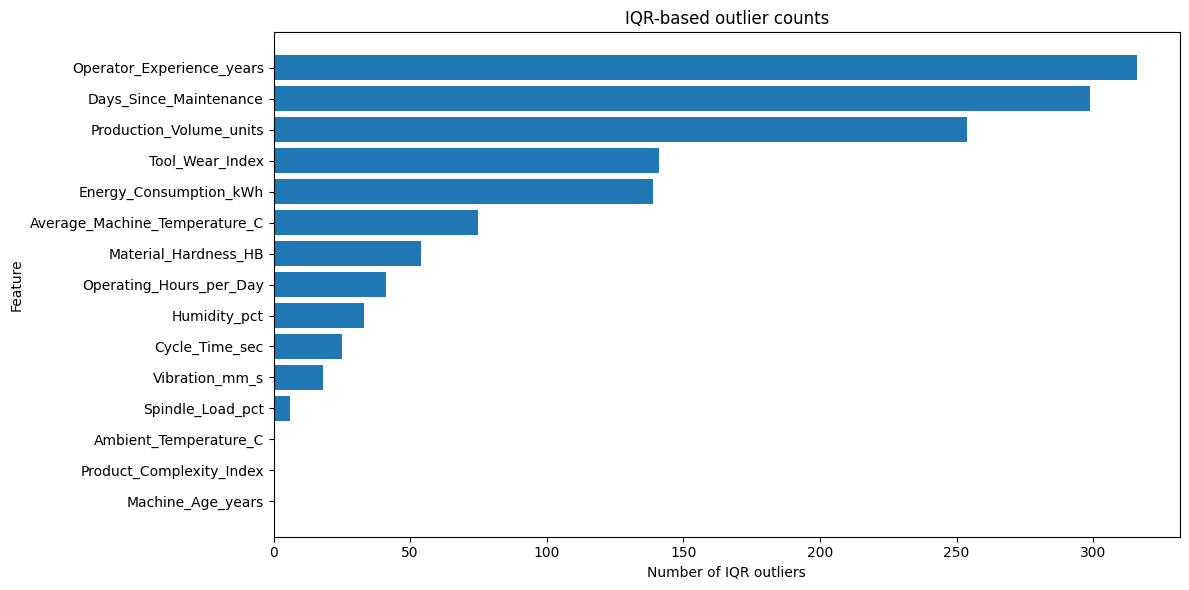

In [16]:
# Outlier counts by numerical feature.
plt.figure(figsize=(12, 6))
plot_df = outlier_table.sort_values("outlier_count")
plt.barh(plot_df["feature"], plot_df["outlier_count"])
plt.xlabel("Number of IQR outliers")
plt.ylabel("Feature")
plt.title("IQR-based outlier counts")
plt.tight_layout()
save_and_show("Figure_11_IQR_Based_Outlier_Counts.png")


In [17]:
# Target-focused outlier inspection.
q1 = df[TARGET].quantile(0.25)
q3 = df[TARGET].quantile(0.75)
iqr = q3 - q1
target_lower = q1 - 1.5 * iqr
target_upper = q3 + 1.5 * iqr

target_outliers = df[
    (df[TARGET] < target_lower) | (df[TARGET] > target_upper)
][[
    ID_COL, "Machine_ID", "Machine_Type", "Shift",
    "Operating_Hours_per_Day", "Production_Volume_units",
    "Product_Complexity_Index", "Spindle_Load_pct",
    "Average_Machine_Temperature_C", "Vibration_mm_s",
    "Tool_Wear_Index", "Days_Since_Maintenance", TARGET
]].sort_values(TARGET, ascending=False)

print(f"Target Q1 = {q1:.2f}")
print(f"Target Q3 = {q3:.2f}")
print(f"Target IQR = {iqr:.2f}")
print(f"Target lower fence = {target_lower:.2f}")
print(f"Target upper fence = {target_upper:.2f}")
print(f"Target outliers = {len(target_outliers)} ({len(target_outliers)/df[TARGET].notna().sum()*100:.2f}% of observed target values)")

display(target_outliers.head(15))


Target Q1 = 260.01
Target Q3 = 348.18
Target IQR = 88.17
Target lower fence = 127.75
Target upper fence = 480.44
Target outliers = 139 (1.46% of observed target values)


,Observation_ID,Machine_ID,Machine_Type,Shift,Operating_Hours_per_Day,Production_Volume_units,Product_Complexity_Index,Spindle_Load_pct,Average_Machine_Temperature_C,Vibration_mm_s,Tool_Wear_Index,Days_Since_Maintenance,Energy_Consumption_kWh
2191,2192,M042,Laser_Cutter,Evening,18.710,492,9.680,98.000,83.450,3.514,0.980,100.000,704.930
9902,9903,M031,Laser_Cutter,Day,21.690,658,9.550,96.900,86.240,3.788,0.799,49.500,698.610
3175,3176,M031,Laser_Cutter,Night,20.190,639,8.670,90.250,86.770,4.263,0.828,97.800,631.590
7000,7001,M021,CNC_Mill,Night,18.500,498,8.100,90.550,88.900,3.715,0.918,100.000,627.430
2720,2721,M035,CNC_Grinder,Evening,16.230,360,9.130,93.820,83.560,NaN,0.932,77.300,609.350
9723,9724,M032,CNC_Lathe,Evening,18.830,569,6.910,75.970,77.420,2.743,NaN,100.000,608.710
7190,7191,M001,CNC_Grinder,Day,21.240,583,8.620,96.460,91.450,3.718,0.691,27.100,607.470
3174,3175,M021,CNC_Mill,Night,21.000,465,9.350,87.200,93.800,3.630,0.980,79.900,602.720
2744,2745,M029,CNC_Mill,Evening,20.210,533,9.650,84.450,91.530,3.572,0.977,100.000,602.630
4375,4376,M039,Laser_Cutter,Day,22.820,1055,8.180,82.210,86.300,3.414,0.912,100.000,596.020


### Outlier interpretation

The IQR screen identifies statistically unusual observations, but an IQR flag alone does not prove a value is invalid. For this dataset, four explicit high-end rules are also audited: `Average_Machine_Temperature_C > 120`, `Cycle_Time_sec > 200`, `Vibration_mm_s > 6`, and `Energy_Consumption_kWh > 800`. The original values are profiled in `df_pre_outlier`; for the main EDA, those values are provisionally set to missing in `df` so they do not dominate summaries and relationship plots.

This decision is provisional and must be confirmed with the lecturer/data owner. The CSV's row structure shows 250 appended records after the first 10,000-row block, including 22 non-identical ID twins; however, only 22 of the 387 extreme-group row flags have a visible twin. Therefore, the appended-row issue does **not** by itself establish the cause of all extreme values. Do not describe these values as confirmed errors until their origin is verified. The full top-15 energy table and the temperature/Fahrenheit diagnostic retain the original values for investigation.


# 8. Relationships among variables

This section addresses the rubric's relationship-analysis criterion using:

- correlation heatmap,
- pair plot,
- parallel-coordinate plot,
- bubble/scatter plot,
- and targeted group comparisons.

The goal is not only to find large correlations but to test whether the relationships suggested by the project scenario are consistent with the observed data.


In [18]:
# Pearson correlation with the target.
target_corr = (
    df[analysis_numeric_cols]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(target_corr.to_frame("Pearson_r_with_target"))


,Pearson_r_with_target
Average_Machine_Temperature_C,0.563
Product_Complexity_Index,0.558
Spindle_Load_pct,0.536
Tool_Wear_Index,0.518
Vibration_mm_s,0.494
Material_Hardness_HB,0.395
Operating_Hours_per_Day,0.372
Days_Since_Maintenance,0.362
Cycle_Time_sec,0.311
Ambient_Temperature_C,-0.247


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_12_Correlation_Heatmap.png


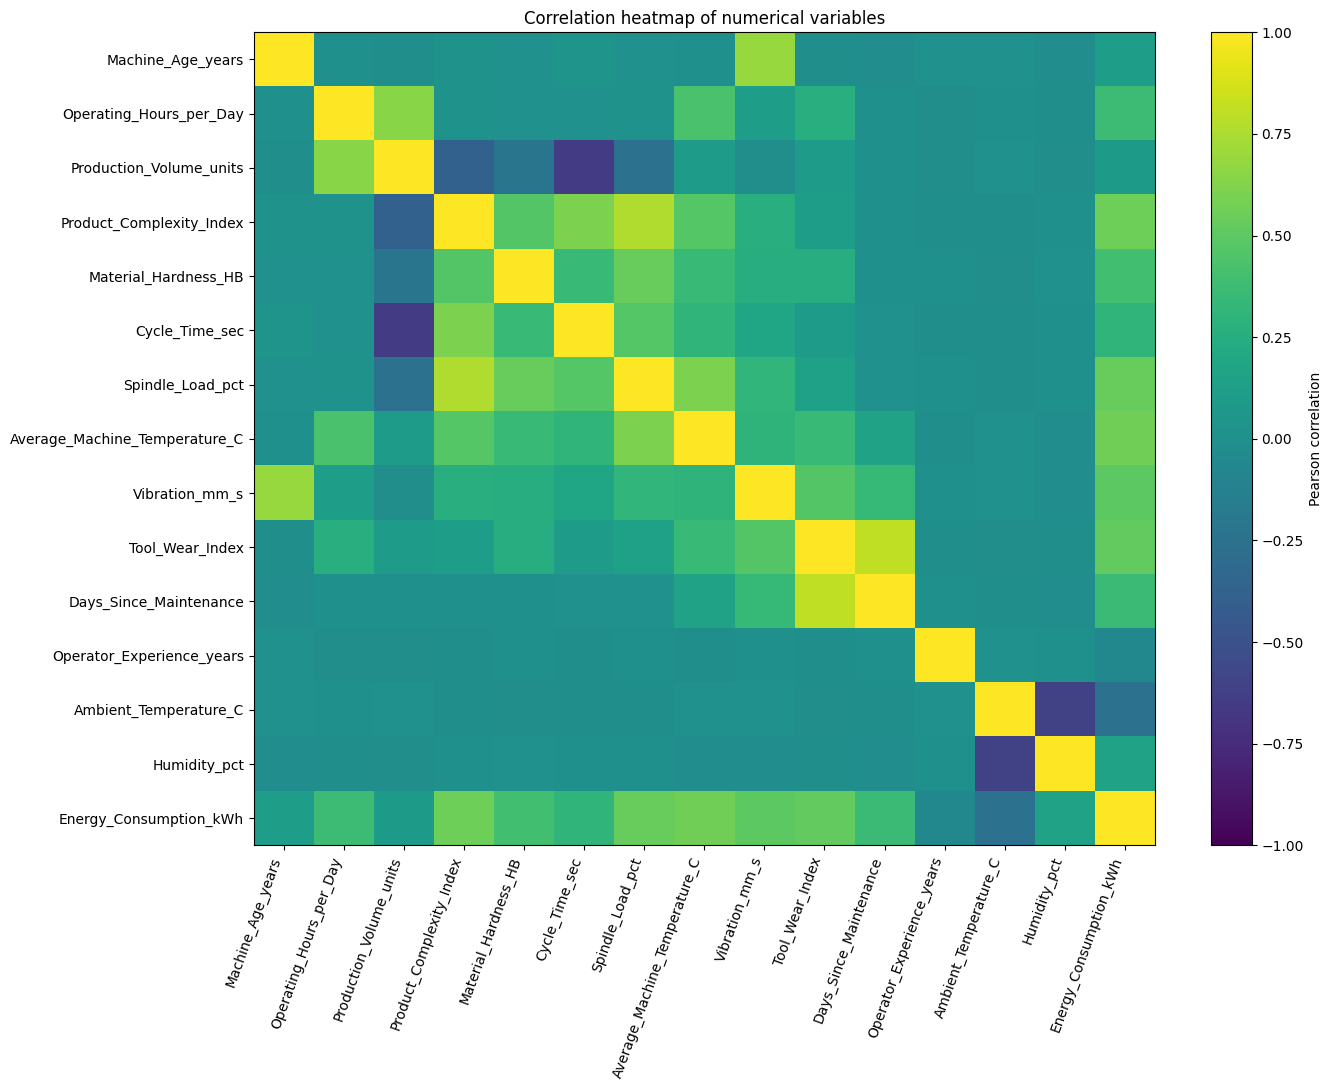

In [19]:
# Correlation heatmap.
corr_matrix = df[analysis_numeric_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(14, 11))
im = ax.imshow(corr_matrix.values, aspect="auto", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_xticklabels(corr_matrix.columns, rotation=70, ha="right")
ax.set_yticklabels(corr_matrix.index)
ax.set_title("Correlation heatmap of numerical variables")
fig.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
save_and_show("Figure_12_Correlation_Heatmap.png")


### Correlation interpretation

Correlations are calculated on the canonical analysis copy after the provisional extreme-value masking, so the flagged tails do not dominate the coefficient estimates. Pearson correlation summarizes linear association; Spearman correlation checks monotonic association and can reveal patterns that are not well represented by Pearson's *r*. Neither establishes causation. Reported associations are weak to moderate (the largest absolute Pearson correlation in the previous unfiltered audit was 0.342), and should be interpreted alongside binned summaries and LOWESS plots.

The original extreme values remain available in `df_pre_outlier` for audit. In particular, the very high energy values appear at otherwise ordinary predictor values in the scatter diagnostics. This contradicts a simple claim that high energy is explained by combinations of extreme predictors. Treat the extreme target values as potential data-quality or target-generation anomalies pending confirmation, rather than asserting that they represent ordinary operational situations.


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_13_Pair_Plot_Scatter_Matrix.png


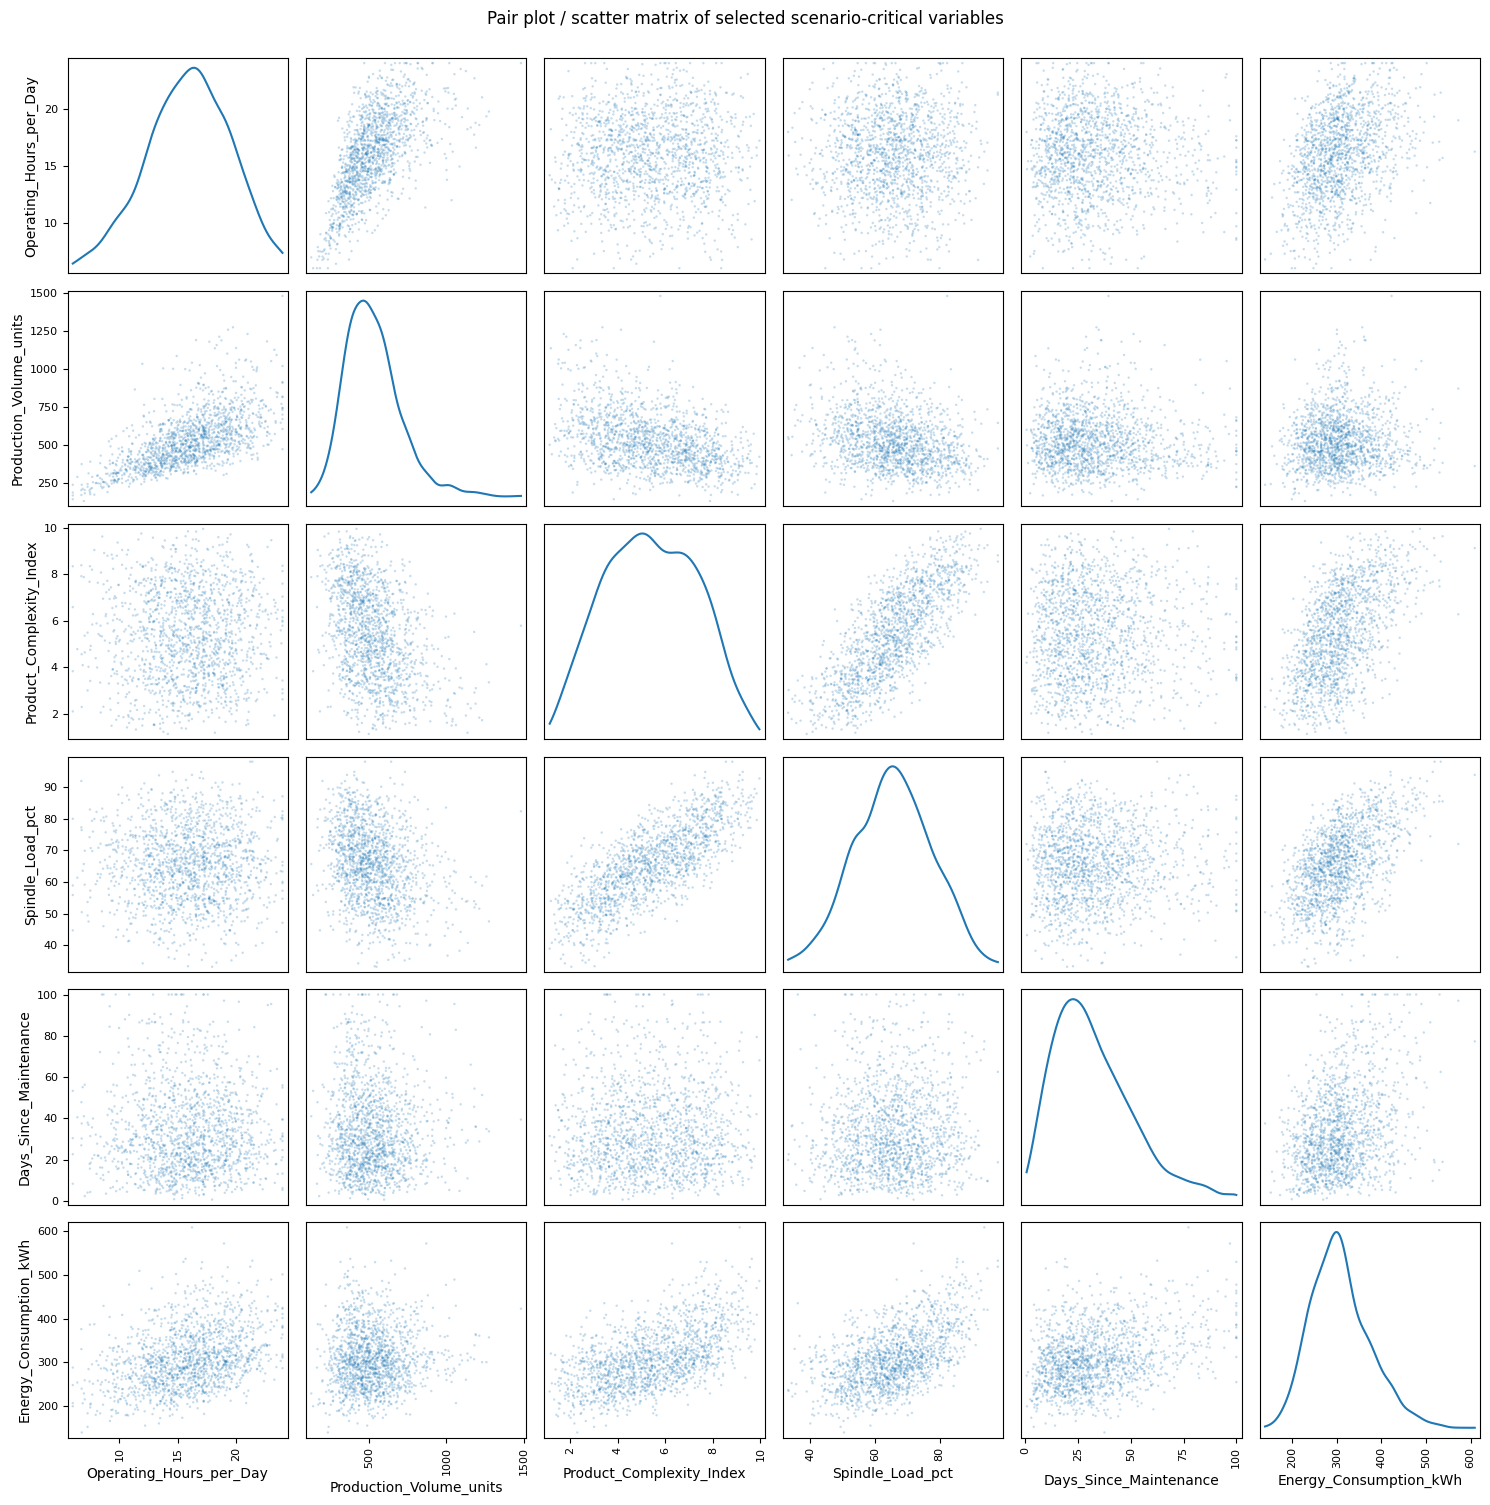

In [20]:
# Pair-plot equivalent: scatter matrix on a reproducible sample.
pair_cols = [
    "Operating_Hours_per_Day",
    "Production_Volume_units",
    "Product_Complexity_Index",
    "Spindle_Load_pct",
    "Days_Since_Maintenance",
    TARGET
]

pair_sample = (
    df[pair_cols]
    .dropna()
    .sample(n=min(1500, df[pair_cols].dropna().shape[0]), random_state=RANDOM_STATE)
)

axes = pd.plotting.scatter_matrix(
    pair_sample,
    figsize=(15, 15),
    diagonal="kde",
    alpha=0.25,
    s=12
)
plt.suptitle("Pair plot / scatter matrix of selected scenario-critical variables", y=1.0)
plt.tight_layout()
save_and_show("Figure_13_Pair_Plot_Scatter_Matrix.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_14_Bubble_Chart_Production_Intensity_and_Energy.png


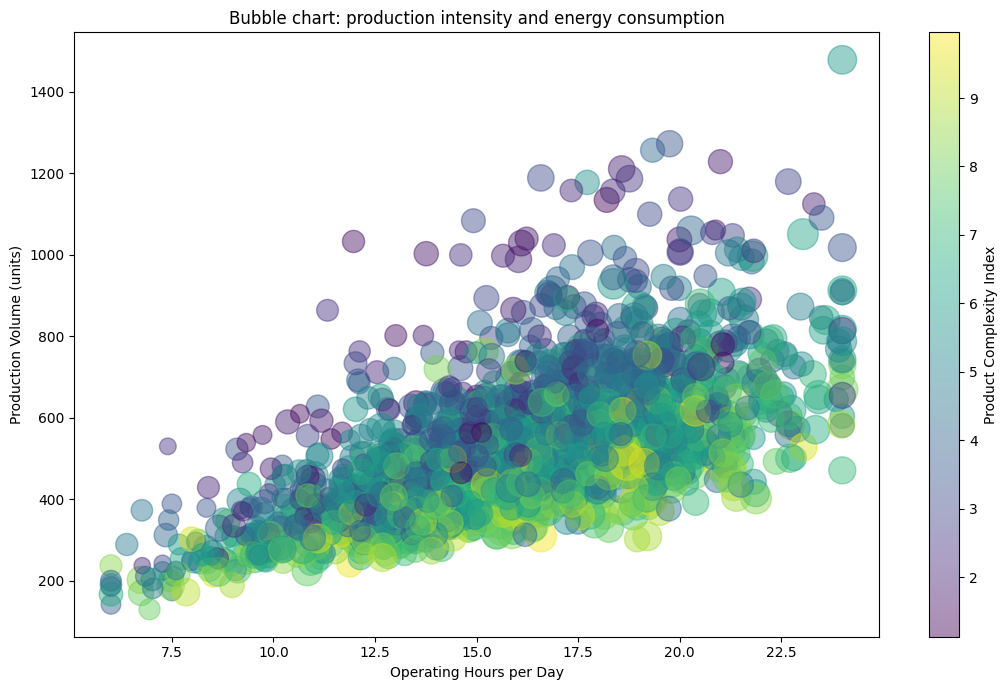

In [21]:
# Bubble chart: operating hours vs production volume, bubble size = target energy.
bubble_df = df[[
    "Operating_Hours_per_Day",
    "Production_Volume_units",
    "Product_Complexity_Index",
    TARGET
]].dropna().sample(
    n=min(1800, df[[
        "Operating_Hours_per_Day",
        "Production_Volume_units",
        "Product_Complexity_Index",
        TARGET
    ]].dropna().shape[0]),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(11, 7))
sizes = np.clip(bubble_df[TARGET], 20, None)
plt.scatter(
    bubble_df["Operating_Hours_per_Day"],
    bubble_df["Production_Volume_units"],
    s=sizes,
    c=bubble_df["Product_Complexity_Index"],
    alpha=0.45,
    cmap="viridis"
)
plt.colorbar(label="Product Complexity Index")
plt.xlabel("Operating Hours per Day")
plt.ylabel("Production Volume (units)")
plt.title("Bubble chart: production intensity and energy consumption")
plt.tight_layout()
save_and_show("Figure_14_Bubble_Chart_Production_Intensity_and_Energy.png")


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_15_Parallel_Coordinates.png


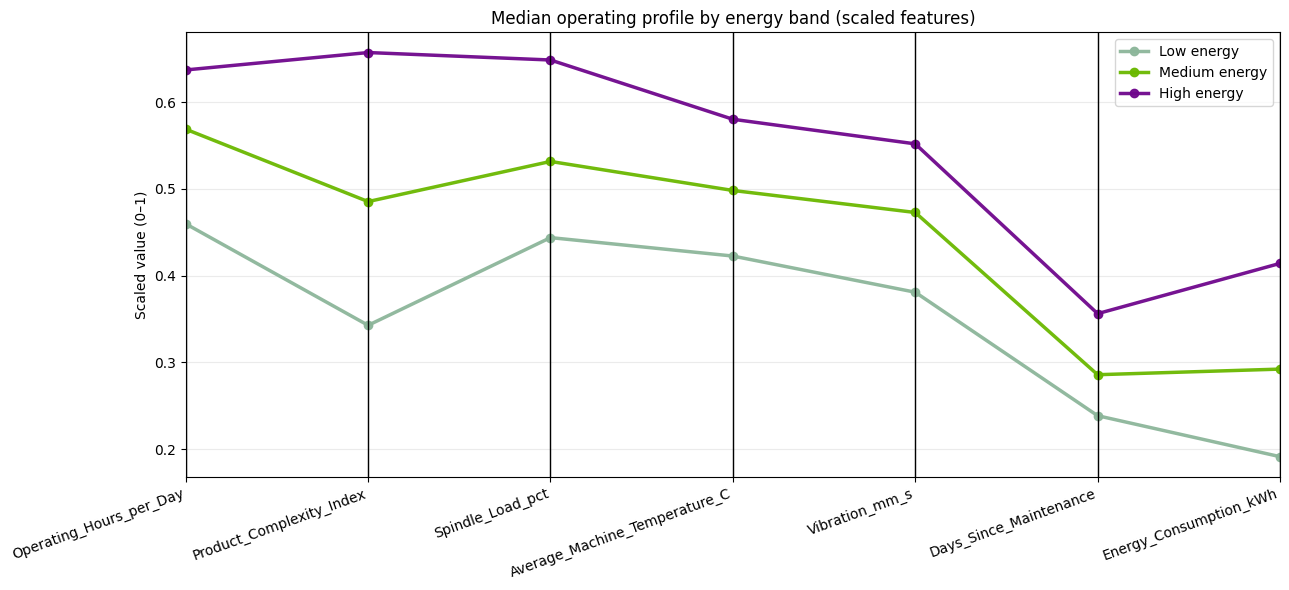

In [22]:
# Readable parallel-coordinates view using energy-band medians, not hundreds of overlapping records.
parallel_cols = [
    "Operating_Hours_per_Day", "Product_Complexity_Index", "Spindle_Load_pct",
    "Average_Machine_Temperature_C", "Vibration_mm_s", "Days_Since_Maintenance", TARGET
]
parallel_df = df[parallel_cols].dropna().copy()
parallel_df["Energy band"] = pd.qcut(parallel_df[TARGET], q=3, labels=["Low energy", "Medium energy", "High energy"], duplicates="drop")
profile = parallel_df.groupby("Energy band", observed=False)[parallel_cols].median().dropna(how="all").reset_index()
scaled = profile.copy()
for col in parallel_cols:
    lo, hi = parallel_df[col].min(), parallel_df[col].max()
    scaled[col] = (scaled[col] - lo) / (hi - lo) if hi > lo else 0.0
plt.figure(figsize=(13, 6))
parallel_coordinates(scaled[parallel_cols + ["Energy band"]], "Energy band", alpha=0.95, linewidth=2.5, marker="o")
plt.title("Median operating profile by energy band (scaled features)")
plt.ylabel("Scaled value (0–1)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
save_and_show("Figure_15_Parallel_Coordinates.png")


# 9. Target-oriented nonlinear pattern investigation

The project brief explicitly states that the data intentionally contains nonlinear patterns such as overload and overheating thresholds, U-shaped operating regions, diminishing returns, and interactions. The following analyses therefore use **binned target means** and focused scatter plots rather than relying only on linear correlation.


In [23]:
def binned_target_summary(column, bins):
    tmp = df[[column, TARGET]].dropna().copy()
    tmp["bin"] = pd.cut(tmp[column], bins=bins, include_lowest=True)
    return tmp.groupby("bin", observed=False)[TARGET].agg(
        count="count",
        mean="mean",
        median="median"
    )

bin_specs = {
    "Spindle_Load_pct": [0, 40, 60, 70, 80, 90, 100],
    "Average_Machine_Temperature_C": [0, 60, 70, 80, 90, 100, 120, 160, 220, 300],
    "Cycle_Time_sec": [0, 60, 80, 100, 120, 160, 220, 400],
    "Days_Since_Maintenance": [0, 15, 30, 45, 60, 80, 100],
    "Operator_Experience_years": [0, 2, 5, 8, 12, 16, 25],
    "Production_Volume_units": [0, 300, 500, 700, 900, 1200, 1800]
}

for col, bins in bin_specs.items():
    print(f"\n{col}")
    display(binned_target_summary(col, bins).round(2))



Spindle_Load_pct


,count,mean,median
bin,,,
"(-0.001, 40.0]",92,269.580,256.120
"(40.0, 60.0]",2970,273.080,269.480
"(60.0, 70.0]",3077,296.440,290.820
"(70.0, 80.0]",2241,333.100,327.400
"(80.0, 90.0]",976,375.950,371.420
"(90.0, 100.0]",149,443.080,430.450



Average_Machine_Temperature_C


,count,mean,median
bin,,,
"(-0.001, 60.0]",36,232.820,239.490
"(60.0, 70.0]",2012,262.430,256.770
"(70.0, 80.0]",5812,309.740,304.540
"(80.0, 90.0]",1158,376.890,370.640
"(90.0, 100.0]",16,508.140,508.900
"(100.0, 120.0]",0,NaN,NaN
"(120.0, 160.0]",0,NaN,NaN
"(160.0, 220.0]",0,NaN,NaN
"(220.0, 300.0]",0,NaN,NaN



Cycle_Time_sec


...

,count,mean,median
bin,,,
"(-0.001, 15.0]",1769,287.500,281.010
"(15.0, 30.0]",3171,296.260,290.940
"(30.0, 45.0]",2254,306.450,301.120
"(45.0, 60.0]",1241,317.520,311.370
"(60.0, 80.0]",706,349.420,341.840
"(80.0, 100.0]",364,406.360,395.190



Operator_Experience_years


,count,mean,median
bin,,,
"(-0.001, 2.0]",1224,314.840,307.760
"(2.0, 5.0]",3245,310.900,303.760
"(5.0, 8.0]",2433,307.100,301.170
"(8.0, 12.0]",1648,303.040,295.920
"(12.0, 16.0]",620,300.220,294.280
"(16.0, 25.0]",335,299.820,292.460



Production_Volume_units


,count,mean,median
bin,,,
"(-0.001, 300.0]",614,287.500,285.360
"(300.0, 500.0]",3978,306.920,300.040
"(500.0, 700.0]",3419,309.330,300.990
"(700.0, 900.0]",1127,312.640,304.010
"(900.0, 1200.0]",323,326.480,320.790
"(1200.0, 1800.0]",44,330.460,322.550


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_16_Binned_Target_Means_Threshold_Behavior.png


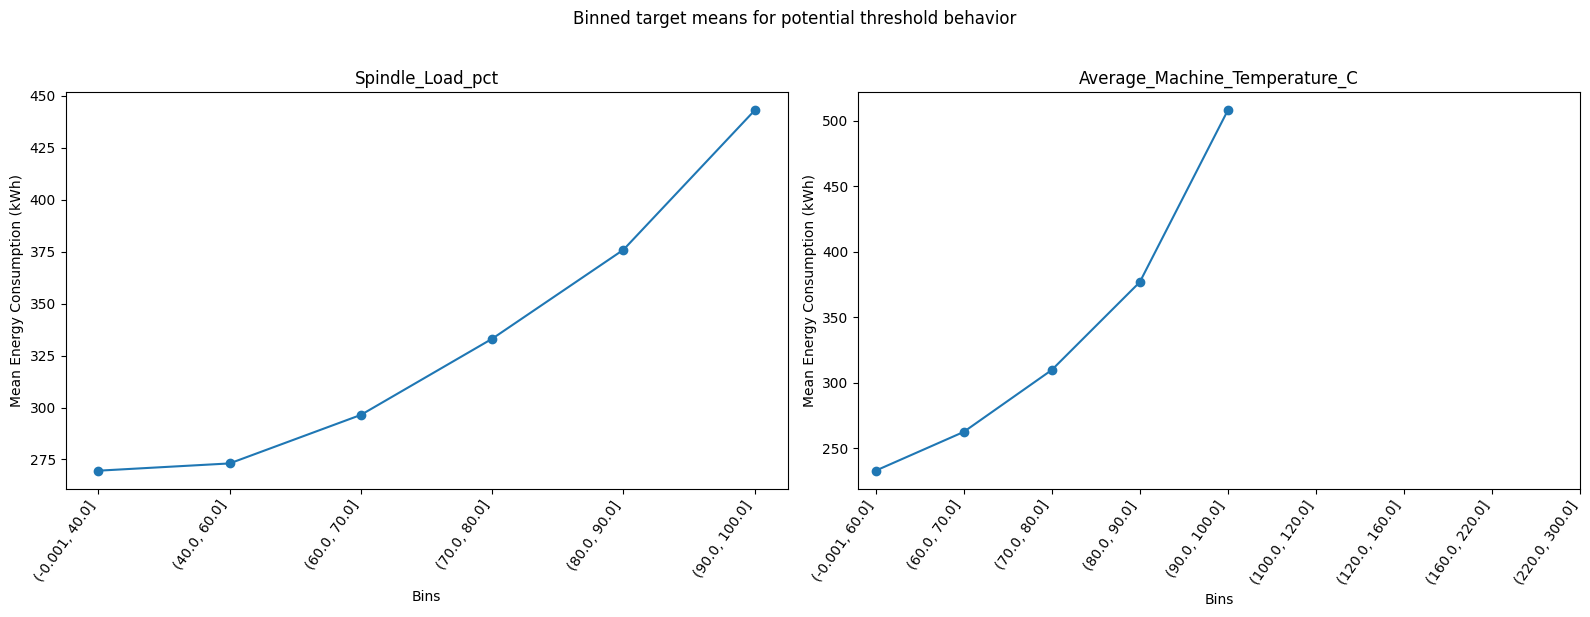

In [24]:
# Binned target means. Plot contiguous valid bins separately so lines never bridge empty bins.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, bins in [
    (axes[0], "Spindle_Load_pct", bin_specs["Spindle_Load_pct"]),
    (axes[1], "Average_Machine_Temperature_C", bin_specs["Average_Machine_Temperature_C"])
]:
    summary = binned_target_summary(col, bins)
    x = np.arange(len(summary))
    y = summary["mean"].to_numpy(dtype=float)
    valid = np.isfinite(y)
    # Split into contiguous valid runs, leaving a visual break wherever a bin is empty.
    start = None
    for i, is_valid in enumerate(valid.tolist() + [False]):
        if is_valid and start is None:
            start = i
        elif not is_valid and start is not None:
            ax.plot(x[start:i], y[start:i], marker="o")
            start = None
    ax.set_title(col)
    ax.set_xlabel("Bins")
    ax.set_ylabel("Mean Energy Consumption (kWh)")
    ax.set_xticks(x)
    ax.set_xticklabels([str(v) for v in summary.index], rotation=55, ha="right")
fig.suptitle("Binned target means for potential threshold behavior", y=1.02)
plt.tight_layout()
save_and_show("Figure_16_Binned_Target_Means_Threshold_Behavior.png")

Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_17_Nonlinear_Trend_Screening_LOWESS.png


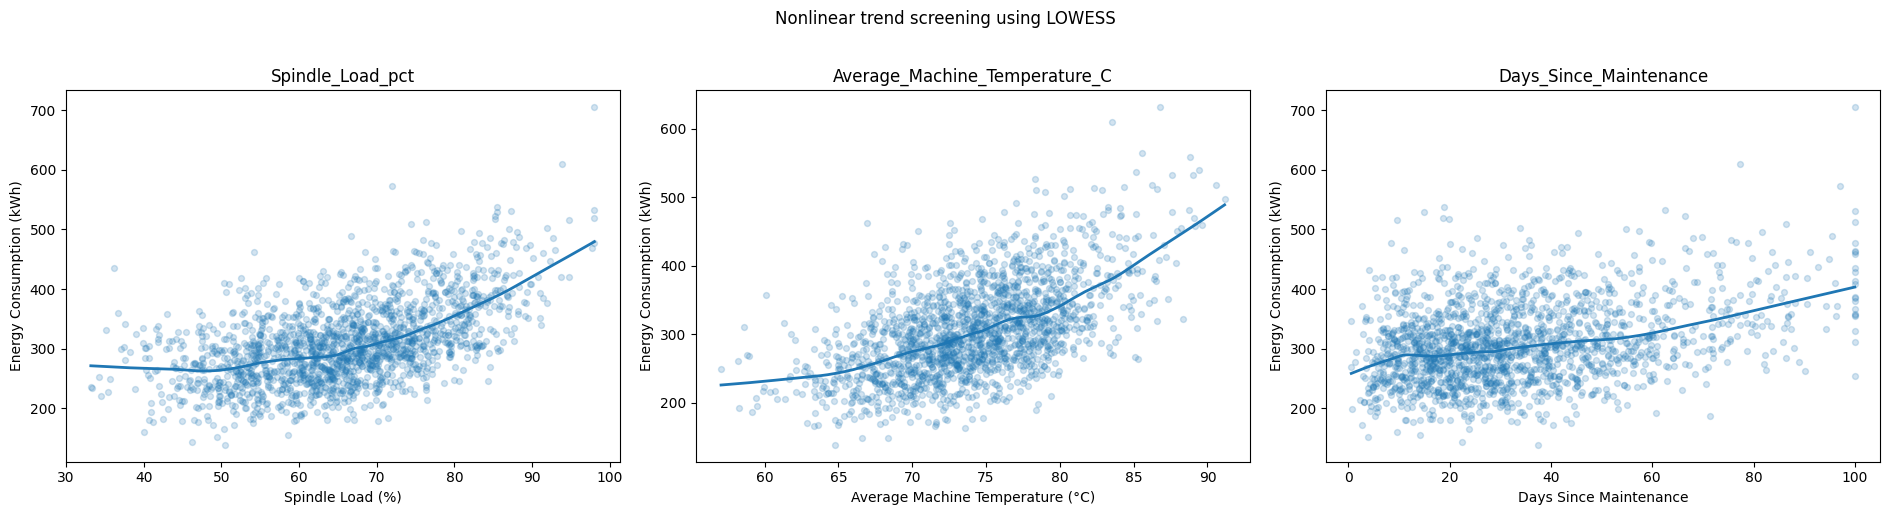

In [25]:
# Direct scatter plots with LOWESS trend lines.
from statsmodels.nonparametric.smoothers_lowess import lowess

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

scatter_specs = [
    ("Spindle_Load_pct", "Spindle Load (%)"),
    ("Average_Machine_Temperature_C", "Average Machine Temperature (°C)"),
    ("Days_Since_Maintenance", "Days Since Maintenance")
]

for ax, (col, label) in zip(axes, scatter_specs):
    sample = df[[col, TARGET]].dropna().sample(
        n=min(1800, df[[col, TARGET]].dropna().shape[0]),
        random_state=RANDOM_STATE
    )
    x = sample[col].to_numpy()
    y = sample[TARGET].to_numpy()
    ax.scatter(x, y, alpha=0.20, s=18)
    order = np.argsort(x)
    smooth = lowess(y[order], x[order], frac=0.25, return_sorted=True)
    ax.plot(smooth[:, 0], smooth[:, 1], linewidth=2)
    ax.set_xlabel(label)
    ax.set_ylabel("Energy Consumption (kWh)")
    ax.set_title(col)

fig.suptitle("Nonlinear trend screening using LOWESS", y=1.02)
plt.tight_layout()
save_and_show("Figure_17_Nonlinear_Trend_Screening_LOWESS.png")


### Nonlinear-pattern interpretation

Binned summaries and LOWESS plots are included because the project brief warns that relationships may be nonlinear. After provisional masking of the flagged extreme values in the analytical copy:

- **Spindle load:** interpret the trend from the binned means and LOWESS curve; the plot is evidence of association, not proof of an overload mechanism.
- **Temperature:** the primary temperature plot now separates valid runs instead of drawing a line across the empty 100–120 °C interval. Values above 120 °C are excluded from the main analysis copy but retained in the audit table.
- **Days since maintenance:** evaluate the shape from the binned and LOWESS summaries without assuming causality.
- **High target values:** the audit shows very high energy values at ordinary predictor values. This contradicts the earlier wording that these may simply represent operational situations explained by extreme conditions. Their provenance and generation rules should be checked before physical interpretation.

All nonlinear hypotheses remain exploratory until the suspected data errors and the dataset boundary are confirmed.


# 10. Group-level energy analysis

Categorical variables can reveal relationships that are hidden in the overall numerical correlation matrix. We therefore compare energy consumption across machine types and shifts, while explicitly reporting group sizes.


In [26]:
group_specs = ["Machine_Type", "Shift"]

for col in group_specs:
    group_summary = (
        df.groupby(col)[TARGET]
        .agg(["count", "mean", "median", "std"])
        .sort_values("mean", ascending=False)
    )
    print(f"\nEnergy consumption by {col}")
    display(group_summary.round(2))



Energy consumption by Machine_Type


,count,mean,median,std
Machine_Type,,,,
Laser_Cutter,1840,336.860,329.360,66.670
CNC_Grinder,2125,311.660,305.410,64.390
CNC_Mill,3441,301.000,293.190,66.010
CNC_Lathe,2099,290.400,284.250,65.390



Energy consumption by Shift


,count,mean,median,std
Shift,,,,
Night,1966,315.730,310.120,67.070
Evening,2710,308.750,300.620,68.380
Day,4824,304.390,297.830,66.940


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_18_19_Energy_by_Machine_Type_and_Shift.png


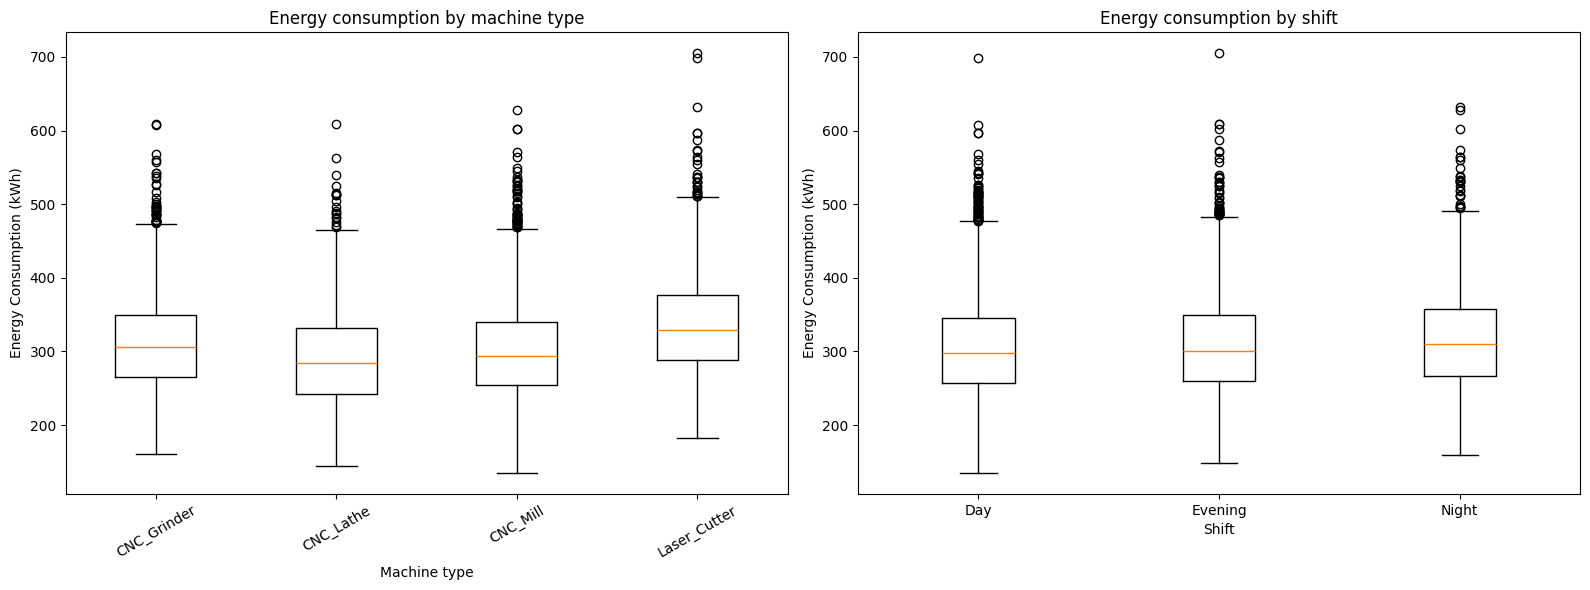

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

machine_groups = [
    g[TARGET].dropna().to_numpy()
    for _, g in df.groupby("Machine_Type")
]
machine_labels = list(df.groupby("Machine_Type").groups.keys())
axes[0].boxplot(machine_groups, labels=machine_labels)
axes[0].set_title("Energy consumption by machine type")
axes[0].set_xlabel("Machine type")
axes[0].set_ylabel("Energy Consumption (kWh)")
axes[0].tick_params(axis="x", rotation=30)

shift_groups = [
    g[TARGET].dropna().to_numpy()
    for _, g in df.groupby("Shift")
]
shift_labels = list(df.groupby("Shift").groups.keys())
axes[1].boxplot(shift_groups, labels=shift_labels)
axes[1].set_title("Energy consumption by shift")
axes[1].set_xlabel("Shift")
axes[1].set_ylabel("Energy Consumption (kWh)")

plt.tight_layout()
save_and_show("Figure_18_19_Energy_by_Machine_Type_and_Shift.png")


# 11. Temporal exploration

`Production_Date` is a date feature and the project brief states that it can be transformed into calendar or seasonal features. For Part 1, we inspect the time dimension without claiming that a temporal pattern is causal.


Saved plot: /Users/subhankarbiswas/MSCM-CO-07_Data-Analytics-in-Supply-Chain-Management_Team_Project/plots-1-updated/Figure_20_Monthly_Mean_Energy_Consumption.png


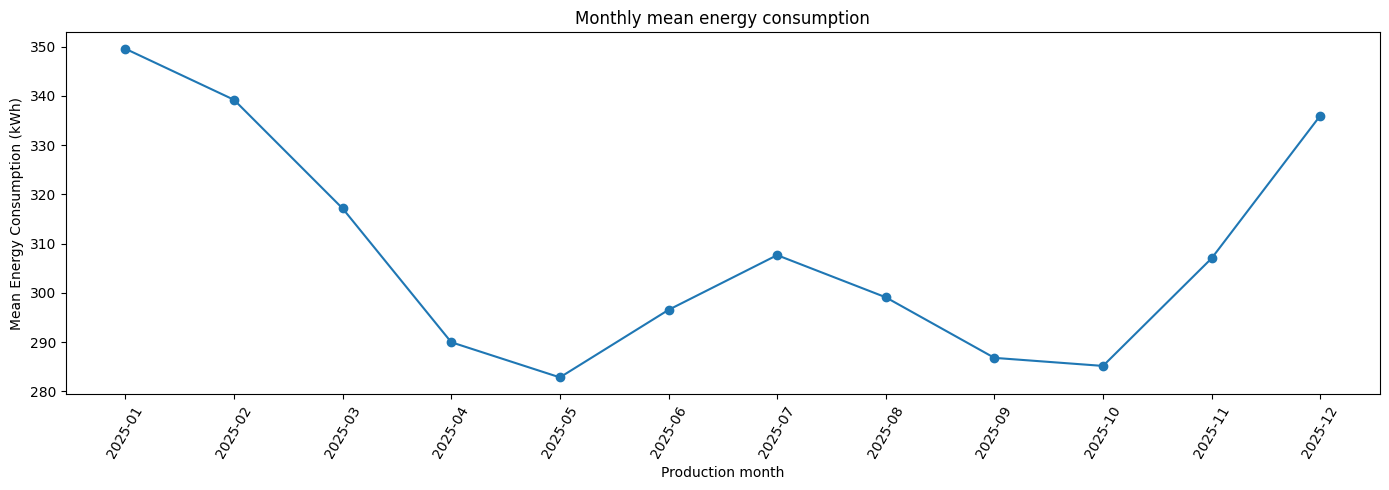

,Production_Month,count,mean,median
0,2025-01,806,349.580,342.040
1,2025-02,728,339.210,331.520
2,2025-03,829,317.150,309.380
3,2025-04,818,289.990,282.140
4,2025-05,764,282.850,273.820
5,2025-06,781,296.560,289.920
6,2025-07,834,307.670,302.960
7,2025-08,827,299.110,293.520
8,2025-09,762,286.810,278.880
9,2025-10,792,285.180,278.520


In [28]:
# Monthly energy overview.
df["Production_Month"] = df[DATE_COL].dt.to_period("M").astype(str)

monthly = (
    df.groupby("Production_Month")[TARGET]
    .agg(["count", "mean", "median"])
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(monthly["Production_Month"], monthly["mean"], marker="o")
plt.xticks(rotation=60)
plt.xlabel("Production month")
plt.ylabel("Mean Energy Consumption (kWh)")
plt.title("Monthly mean energy consumption")
plt.tight_layout()
save_and_show("Figure_20_Monthly_Mean_Energy_Consumption.png")

display(monthly.round(2))


# 12. Consolidated evidence table for brainstorming

The table below provides quantitative evidence that can be cited directly in the brainstorming section. It combines target correlations, group means, missingness, and IQR outlier counts.


In [29]:
# Strongest absolute correlations.
strong_corr = target_corr.abs().sort_values(ascending=False).head(8).to_frame("abs_Pearson_r")
strong_corr["Pearson_r"] = target_corr.loc[strong_corr.index]
strong_corr = strong_corr[["Pearson_r", "abs_Pearson_r"]]

print("Strongest target correlations:")
display(strong_corr.round(3))

print("\nMachine type target means:")
display(
    df.groupby("Machine_Type")[TARGET]
      .agg(["count", "mean", "median"])
      .sort_values("mean", ascending=False)
      .round(2)
)

print("\nShift target means:")
display(
    df.groupby("Shift")[TARGET]
      .agg(["count", "mean", "median"])
      .sort_values("mean", ascending=False)
      .round(2)
)

print("\nHighest missingness:")
display(missing_table[missing_table["missing_count"] > 0].head(10))

print("\nLargest IQR outlier counts:")
display(outlier_table.head(10).round(2))


Strongest target correlations:


,Pearson_r,abs_Pearson_r
Average_Machine_Temperature_C,0.563,0.563
Product_Complexity_Index,0.558,0.558
Spindle_Load_pct,0.536,0.536
Tool_Wear_Index,0.518,0.518
Vibration_mm_s,0.494,0.494
Material_Hardness_HB,0.395,0.395
Operating_Hours_per_Day,0.372,0.372
Days_Since_Maintenance,0.362,0.362



Machine type target means:


,count,mean,median
Machine_Type,,,
Laser_Cutter,1840,336.860,329.360
CNC_Grinder,2125,311.660,305.410
CNC_Mill,3441,301.000,293.190
CNC_Lathe,2099,290.400,284.250



Shift target means:


,count,mean,median
Shift,,,
Night,1966,315.730,310.120
Evening,2710,308.750,300.620
Day,4824,304.390,297.830



Highest missingness:


,missing_count,missing_pct
Tool_Wear_Band,600,6.000
Tool_Wear_Index,600,6.000
Vibration_mm_s,592,5.920
Energy_Consumption_kWh,495,4.950
Average_Machine_Temperature_C,494,4.940
Humidity_pct,300,3.000
Cycle_Time_sec,101,1.010
Shift,5,0.050



Largest IQR outlier counts:


,feature,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_pct
0,Operator_Experience_years,3.070,8.360,5.290,-4.860,16.290,316,3.160
1,Days_Since_Maintenance,18.000,44.600,26.600,-21.900,84.500,299,2.990
2,Production_Volume_units,405.000,629.000,224.000,69.000,965.000,254,2.540
3,Tool_Wear_Index,0.310,0.530,0.220,-0.010,0.860,141,1.500
4,Energy_Consumption_kWh,260.010,348.180,88.170,127.750,480.440,139,1.460
5,Average_Machine_Temperature_C,70.380,77.550,7.170,59.620,88.300,75,0.790
6,Material_Hardness_HB,230.100,275.900,45.800,161.400,344.600,54,0.540
7,Operating_Hours_per_Day,13.530,18.470,4.940,6.120,25.880,41,0.410
8,Humidity_pct,52.860,66.940,14.080,31.740,88.060,33,0.340
9,Cycle_Time_sec,75.060,100.340,25.280,37.130,138.270,25,0.250


# 13. Brainstorming: findings, hypotheses, and questions

This section is deliberately separated into **observed findings**, **testable hypotheses**, and **open questions**. That distinction prevents an EDA association from being presented as a causal conclusion.

## 13.1 Finding 1 — Higher spindle load is associated with higher energy consumption

**Evidence:** Figure 12 shows a positive Pearson association between `Spindle_Load_pct` and the target, while Figure 16 shows the binned target means and Figure 17 provides the LOWESS view of spindle load, temperature, and days since maintenance.

**Interpretation:** Higher machine/process load is associated with higher energy consumption in the supplied observations. The pattern is consistent with the project scenario's description of a potential overload penalty.

**Hypothesis H1:** Energy consumption increases nonlinearly as spindle load approaches the upper operating range.

**Question:** Is there a threshold above which the marginal energy cost of additional spindle load increases sharply?

---

## 13.2 Finding 2 — Machine temperature is related to energy consumption, but the extreme tail needs investigation

**Evidence:** Figure 12 provides the linear correlation, while Figures 8–10 and Figure 17 show the distribution and nonlinear trend. The dataset contains a small number of very high temperature values beyond the main operating range.

**Interpretation:** Energy is higher across much of the higher-temperature operating range, but the high-temperature tail is provisionally masked in the analysis copy. The data alone cannot establish whether these values are deliberate cases or data errors; confirm with the lecturer/data owner.

**Hypothesis H2:** Energy consumption increases more rapidly after a machine-temperature threshold.

**Question:** Do the extreme temperature observations correspond to systematically different machine types, operating loads, or maintenance conditions?

---

## 13.3 Finding 3 — Longer time since maintenance is associated with higher energy consumption

**Evidence:** Figure 12 shows a positive association between `Days_Since_Maintenance` and energy, while Figure 17 provides the LOWESS trend for days since maintenance. The binned maintenance-delay table should be interpreted alongside that figure.

**Interpretation:** The observed association is consistent with the project scenario's equipment-condition and maintenance framing.

**Hypothesis H3:** The energy penalty associated with additional days since maintenance is nonlinear and becomes stronger after a maintenance-delay threshold.

**Question:** Does maintenance delay interact with `Tool_Wear_Index`, `Vibration_mm_s`, or `Machine_Age_years`?

---

## 13.4 Finding 4 — Product complexity and spindle load are candidate production/process drivers

**Evidence:** Figure 12 identifies `Product_Complexity_Index` and `Spindle_Load_pct` among the more strongly associated numerical variables with the target. Figure 14 also jointly visualizes operating hours, production volume, product complexity, and energy.

**Interpretation:** More complex production requirements may be associated with higher energy use, but production volume alone has a comparatively weak linear association in the raw data.

**Hypothesis H4:** Product complexity has a stronger effect on energy when combined with high spindle load or long operating hours.

**Question:** Are interactions between complexity and machine condition more informative than either variable alone?

---

## 13.5 Finding 5 — High-energy observations conflict with ordinary predictor values

**Evidence:** Figure 9 shows the target's box-plot structure, Figure 11 identifies IQR-based target outliers, and the target-focused table lists the highest observations.

**Interpretation:** The original high-energy observations are retained in the audit table but provisionally set to missing in the main analysis copy. Because very high energy appears at ordinary predictor values, the prior explanation that these values may simply represent operational situations is not supported. Confirm the target-generation rules and data provenance with the lecturer/data owner.

**Assessment of H5:** This hypothesis is **not supported by the observed scatter**. Figure 17 shows very high energy values at ordinary predictor values, so a simple combination-of-extremes explanation is not justified. Investigate the target-generation process and data provenance before proposing a physical explanation.

**Question:** Why do very high energy values occur at otherwise ordinary predictor values, and are these values consistent with the intended data-generation rules?

---

## 13.6 Finding 6 — Data-quality issues must be resolved before final modeling

**Evidence:** The integrity checks show 10,250 raw rows, 228 exact duplicates, 22 repeated non-identical `Observation_ID` values after exact de-duplication, missing target values, and ten rows with unexpected category values (`Tree` and `Dream`) that are excluded from the analysis copy. Figure 2 documents missingness.

**Interpretation:** These are not merely cosmetic issues. They can affect model training, group comparisons, and feature engineering.

**Hypothesis H6:** Some apparent extreme patterns may be influenced by data-quality anomalies rather than production behavior.

**Question:** Are duplicate identifiers intentional repeated machine-day observations, accidental duplicates, or rows with altered measurements? Are `Tree` and `Dream` data-entry errors or intentionally injected anomalies?

**Part 1 decision:** Preserve `df_raw`; remove exact duplicate rows in the analysis copy, exclude the ten rows with undocumented categorical labels, and retain the 22 repeated non-identical IDs for explicit source-level investigation rather than choosing records arbitrarily.


# 14. Brainstorming matrix — evidence to next analysis

| Evidence / finding | Figure(s) / table(s) | Hypothesis | Next analysis |
|---|---|---|---|
| Higher spindle load corresponds to higher energy | Figures 12, 16, 17 | H1: upper-load nonlinear penalty | Piecewise regression / spline / tree-based comparison |
| Higher temperature is associated with higher energy in the main range | Figures 8–10, 12, 17 | H2: overheating threshold | Threshold analysis; inspect extreme-temperature rows |
| Energy rises with maintenance delay | Figures 12, 17 | H3: nonlinear maintenance penalty | Interaction with tool wear and vibration |
| Complexity and process load are associated with energy | Figures 12, 14 | H4: interaction effect | 2D interaction plots / feature interaction analysis |
| Target has high-end IQR outliers | Figures 9, 11, 17 and the top-15 table | H5 is not supported: very high energy occurs at ordinary predictor values | Investigate target-generation rules and data provenance |
| Missingness and category/ID anomalies exist | Figure 2 and integrity checks | H6: data-quality anomalies can distort analysis | Validate source generation rules before modeling |

This matrix provides explicit cross-references from each brainstorming statement to the notebook evidence, satisfying the project's requirement that statements be supported by images or text parts.


# 15. Project Part 1 conclusion

### What the EDA establishes

1. The supplied CSV has 10,250 rows and 20 columns. The first 10,000 rows contain unique Observation_ID values 1–10,000; the appended 250 rows repeat that ID range and are excluded provisionally from the primary analysis.
2. `Energy_Consumption_kWh` is the regression target specified by the project.
3. Missing values occur in several process/environment variables and in the target itself.
4. Five Tree machine-type labels are corrected using Machine_ID mappings; five Dream shifts are marked missing. Extreme values are provisionally masked in the analysis copy, with original values retained for audit and data-owner confirmation.
5. Pearson relationships are weak to moderate; the largest absolute correlation is 0.342. Spearman correlations and correlations after excluding the defined extreme groups are also reported.
6. The relationship structure is not adequately described by Pearson correlation alone; Spearman correlations, binned means, interactions, and LOWESS plots provide additional diagnostics.
7. Potential outliers are audited in the unmasked copy and provisionally set to missing in the main EDA copy. Very high energy values at ordinary predictor values contradict a simple operational-extremes explanation; confirm the source-generation rules.
8. The main hypotheses concern **overload thresholds, overheating thresholds, maintenance-delay effects, and interactions between production requirements and machine condition**.

### Modeling preparation

For the later regression stage, the analysis suggests that the workflow should explicitly address:

- missing predictor and target values;
- anomalous categorical levels;
- duplicate `Observation_ID` values;
- appropriate treatment of `Production_Date`;
- nonlinear relationships;
- interactions;
- and the distinction between genuine operational extremes and data-quality errors.

No final modeling decision is made in this Part 1 notebook.


# 16. External references

The following sources support the EDA methodology used in this notebook. They are methodological references, not sources of facts about the supplied manufacturing dataset.

1. **Heckert, N. A., & Filliben, J. (2003).** *NIST/SEMATECH e-Handbook of Statistical Methods — Chapter 1: Exploratory Data Analysis.* National Institute of Standards and Technology (NIST).  
   https://www.nist.gov/publications/nistsematech-e-handbook-statistical-methods-chapter-1-exploratory-data-analysis

2. **NIST/SEMATECH Engineering Statistics Handbook.** *What are outliers in the data?*  
   https://www.itl.nist.gov/div898/handbook/prc/section1/prc16.htm

3. **pandas documentation.** `pandas.read_csv` and missing-value parsing behavior.  
   https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html

4. **scikit-learn documentation.** *Imputation of missing values.*  
   https://scikit-learn.org/stable/modules/impute.html

### Methodological note

NIST describes EDA as a graphical/statistical approach intended to uncover structure, detect unusual observations, and inform later modeling. The notebook follows that philosophy by combining distributions, outlier screening, correlations, relationship plots, grouped comparisons, and hypothesis generation rather than relying on one statistic alone.


# Appendix A — Reusable diagnostic code

The following compact cells can be reused during later revisions of the project without changing the raw dataset.


In [30]:
# Raw-data snapshot for reproducibility
print("Raw dataset shape:", df_raw.shape)
print("Raw columns:")
for i, c in enumerate(df_raw.columns, start=1):
    print(f"{i:02d}. {c}")

print("\nRaw missing-value counts:")
display(df_raw.isna().sum().to_frame("missing_count"))

print("\nRaw categorical levels:")
for c in ["Machine_Type", "Shift"]:
    print(c, sorted(df_raw[c].dropna().unique().tolist()))


Raw dataset shape: (10250, 20)
Raw columns:
01. Observation_ID
02. Production_Date
03. Machine_ID
04. Machine_Type
05. Shift
06. Machine_Age_years
07. Operating_Hours_per_Day
08. Production_Volume_units
09. Product_Complexity_Index
10. Material_Hardness_HB
11. Cycle_Time_sec
12. Spindle_Load_pct
13. Average_Machine_Temperature_C
14. Vibration_mm_s
15. Tool_Wear_Index
16. Days_Since_Maintenance
17. Operator_Experience_years
18. Ambient_Temperature_C
19. Humidity_pct
20. Energy_Consumption_kWh

Raw missing-value counts:


,missing_count
Observation_ID,0
Production_Date,0
Machine_ID,0
Machine_Type,0
Shift,0
Machine_Age_years,0
Operating_Hours_per_Day,0
Production_Volume_units,0
Product_Complexity_Index,0
Material_Hardness_HB,0



Raw categorical levels:
Machine_Type ['CNC_Grinder', 'CNC_Lathe', 'CNC_Mill', 'Laser_Cutter', 'Tree']
Shift ['Day', 'Dream', 'Evening', 'Night']
